# [1] 04 Creep-event detection, size, extent and the slip budget

```
Created on Thu Sep 24 2026
@author: daniellelindsay
Run in opera_disp_feb13. The bootstraps and the per-crossing fits take a few minutes.
```

**What this notebook does.** This is the only place event dates are defined:
every later notebook reads `creep_events.csv` from here.

1. **Detect** the events on the stacked fault-parallel series of the Tule Pond
   section (crossings within +/-2 km along the trace of the section centre;
   until 2026-10-05 +/-2 km of LATITUDE, ~+/-2.3 km along strike): remove rate + annual
   cycle, run a matched filter for a step (mean of the next 3 epochs minus the
   previous 3), flag where it exceeds 3 robust sigma. Oakland (COZ1) is run the
   same way as the positive control: its creepmeter records the same events.
2. **Size and timing** from ONE joint model per stack (linear + annual + a step
   per event), grid-searching each step over the acquisition epochs. The onset
   window runs from the last acquisition before the step (`onset_lo`) to the
   first acquisition after it (`onset_hi`): one acquisition interval, 6 or 12 d.
   Amplitude CIs are block bootstraps.
3. **Along strike**: the same joint model at every crossing with the step epochs
   held fixed gives per-event slip profiles, the inter-event (secular) rate
   and the event-driven fraction of slip.
4. **Section lengths**: (a) the length of fault hosting the events, where the
   cumulative event slip departs from zero (threshold from the flank scatter);
   (b) the width of the peak slip zone at 75% and 90% of the peak fraction.
5. **Band stack**: the joint model on the mean of the peak-zone crossings, the
   numbers the paper quotes for the five events.
6. **Slip budget**: secular + event-driven rate (the five Tule Pond events
   only) against the alignment arrays (refit over the InSAR window, and their
   whole-record rates) and creepmeters.
7. Bo Xie's relocated seismicity and the repeating earthquakes near the section: how many
   fall within 2 km of the trace in the section hosting the events and in the 90 % band over
   the InSAR period. (No recurrence intervals here: the paper's interval statistics have ONE
   definition and one owner, notebook 11; the point-onset intervals this notebook registered until
   2026-10-06, `04_interval_*`, are retired.)

PREPUB: Ported from `Hayward_DISP-S1/analysis/run12_detect_events.py`,
PREPUB: `run14_event_fraction.py`, `hayward_creep/plotting/plot_event_summary.py` and
PREPUB: `plot_slip_budget.py`.
One stream everywhere: 30 to 150 m, coherence 0.7.

**Inputs**: `03_creep_timeseries/fp_ts.csv`, `02_velocity_decomposition/fp_velocity_map.h5`,
the fault trace, the alignment-array summary and survey files, the five
creepmeter records, the GrowClust catalogue and the two repeater catalogues.

**Outputs** (`outputs/04_event_detection/`): `creep_events.csv` (one row per
event: the onset window `onset_lo` to `onset_hi`, in decimal years, its first
calendar day `onset_day`, the label of the COZ1 events in the registry, and the
step size), `creepmeter_events_COZ1.csv` (the creepmeter's own detections,
`detect_yr` = the time of the detector's flag), `event_fraction_by_crossing.csv`,
`section_lengths.csv`, `band_stack_75pct.csv`, `band_stack_90pct.csv`,
`slip_budget_by_crossing.csv`, `aa_rates.csv`, `creepmeter_rates.csv`,
`04_events_stats.txt`, registry rows `04_*`.

**Figures** (in the dated figure folder, .png and .pdf):
`figS_event_detection_<params>_k3_win3` (detection QC, supplement);
`fig1_tulepond_<params>_band90` (Fig 1: rotated map, hovmoller, per-event
profiles, rate budget, band stack); `figS_slip_budget_<params>` (the slip
budget along the whole fault, supplement).

**What to check.** Five Tule Pond events, two years apart, each about 10 mm on
the band stack; the two large COZ1 events (January 2019, February 2022) also
seen by its creepmeter, and since the along-trace stack (2026-10-05) a third,
smaller COZ1 event in October 2022 (the creepmeter's surge from 2022-09-17 and
its event of 2022-10-24, Gittins et al. 2026; kept as a control event, Dani
2026-10-05). The COZ1 events are labelled by onset day, not year; a
median event-driven fraction of ~76% near the Tule Pond centre (21%
at the Oakland control); the budget closing (secular + event-driven ~ the
long-term array rate of ~6 to 6.5 mm/yr). The CHECK cell [11] repeats the
detection at 3.5 and 4 times the noise level and asserts the same five events,
and asserts that every onset window agrees with each track's real acquisitions.

In [1]:
# [2]
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, segments, creepmeters, params, coh_timeseries, insar_dic_list,
                                max_interp_gap_days, profile_smooth_km, creepmeter_glitches, paper_band_frac,
                                coz1_large_events_yr, coz1_large_tol_days,
                                paths_out, repo_dir)   # profile_smooth_km: Fig 1C and 1D, one Gaussian (0.2 km); creepmeter_glitches: the listed glitch days

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # the FP velocity map from 02
import xarray as xr                              # grids for pygmt
import matplotlib.pyplot as plt
import pygmt

## [3] Paths and parameters

In [2]:
# [4]
notebook = "04_event_detection"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the detector
stack_half_km = 2.0     # half-width of the peak-slip stack about the section centre, km ALONG THE TRACE
#                         (lat_to_km_map; until 2026-10-05 it was km of latitude, ~+/-2.3 km along strike);
#                         a whole-section average dilutes the transient with non-slipping fault
win_n = 3               # epochs each side in the matched filter (3 x ~6 d: sharp against months-long wander)
k_sigma = 3.0           # detection threshold in robust sigma of the statistic
merge_yr = 0.15         # flags closer than this are one event
step_search_yr = 0.10   # grid-search the step epoch over acquisition epochs within this of the detection
nboot = 2000            # block bootstrap resamples for the amplitude CIs
block_years = 1.0       # bootstrap block length (years)
seed = 0                # bootstrap random seed

# along strike
min_epoch_frac = 0.5    # a crossing needs >50% finite epochs to be fitted
smooth_km = 0.4         # along-fault smoothing of the profiles (gap-preserving; sigma in km along the trace)
total_floor_mm = 1.0    # |total slip| below this: fraction undefined
band_fracs = (0.75, 0.90)   # the peak slip zone: fraction >= this x its local peak
band_main = paper_band_frac  # the band the figures draw and the paper quotes (TulePond_filepaths, also read by 11)
assert band_main in band_fracs, f"the paper's band {band_main} is not one of the bands computed {band_fracs}"
flank_km = ((52.0, 56.0), (64.0, 68.0))   # flanks used for the creep-length threshold (Tule Pond)
seis_max_dist_km = 2.0  # seismicity and repeaters within this of the trace
neg_floor_frac = 0.2    # hovmoller colour scale starts at -this x vmax so early-epoch noise is not clipped to white

# the slip budget and the alignment arrays
aa_min_surveys = 4      # an array is refit over the InSAR window only with this many surveys ...
aa_min_span_yr = 5.0    # ... spanning at least this many years
aa_max_dist_km = 2.0    # alignment arrays within this of the trace
km_lim = (15.0, 70.0)   # x range of the supplement slip-budget figure (km from Point Pinole)
strike_map = 144.0      # page rotation of the map panel (mean strike, notebook 02)
ref_patch_km = 5.0      # map display reference: CTM1-COZ1 patch, +/- this across the fault

# the two sections: (title, segment key, fraction column, seed centre km, half-span km, creepmeter)
SEGS = [("Tule Pond", "TULEPOND", "tulepond", 58.0, 10.0, ""),
        ("Oakland (control)", "COZ1", "coz1", 32.0, 15.0, "COZ1")]

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")
# each track's REAL acquisition dates (the columns of 03's per-track LOS tables), for the window check [12]
track_files = {}
for dic in insar_dic_list:
    track_files[dic["ORBIT_DIRECTION"]] = os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{dic['ORBIT_DIRECTION']}.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
creepmeter_files = []
for code, lat, lon, name in creepmeters:
    creepmeter_files.append(utils.creepmeter_file(common_paths["creepmeter_dir"], code))
REG.inputs(fp_ts_file, map_file, *track_files.values(), common_paths["fault_profiles"], common_paths["aa_summary"],
           common_paths["CRE_Taira"], common_paths["CRE_Wald"], common_paths["growclust_cat"],
           *creepmeter_files)

Registry for 04_event_detection: run a270b6d7, git 6168603


## [5] Load: the fault-parallel time series, the along-fault axis, the trace

In [3]:
# [6]
# the fault-parallel time series from 03: lat x decimal year, mm, rows south -> north
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_ts = fp_ts.sort_index()
lats = fp_ts.index.values
dates = fp_ts.columns.values.astype(float)
fp_matrix = fp_ts.values
t0, t1 = float(dates.min()), float(dates.max())
span = t1 - t0

# the along-fault axis: km from Point Pinole, increasing south
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])
km = to_km(lats)
north_to_south = np.argsort(km)
km_sorted = km[north_to_south]
lats_sorted = lats[north_to_south]


def lat_of_km(km_value):
    """Latitude of the crossing at km_value from Point Pinole (linear interpolation along the sorted axis)."""
    return float(np.interp(km_value, km_sorted, lats_sorted))


x_fault = pd.read_csv(common_paths["fault_profiles"])
print(f"fp_ts: {len(lats)} crossings ({km.min():.1f} to {km.max():.1f} km from Point Pinole) x {len(dates)} epochs, "
      f"{t0:.3f} to {t1:.3f} ({span:.2f} yr); coherence {coh_timeseries}")


def load_stack(seg):
    """Mean of the fp_ts rows within +/- stack_half_km ALONG THE TRACE of the section centre (rows with >50%
    valid epochs). Returns (dates, stack_mm, n_crossings) at the epochs where the mean is finite."""
    centre_km = float(to_km([seg["lat"]])[0])          # fp_ts is indexed by latitude; km is its along-trace position
    nearby = fp_ts[np.abs(km - centre_km) <= stack_half_km + 1e-6]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(stack)
    return dates[ok], stack[ok], len(nearby)

fp_ts: 611 crossings (0.0 to 68.4 km from Point Pinole) x 439 epochs, 2016.672 to 2026.216 (9.54 yr); coherence 0.7


## [7] The detector and the joint model

A creep event is a STEP in the residual after rate + annual cycle. The
residual wanders by +/-2 mm over months (residual atmosphere), comparable to
the step sizes, so the detector keys on sharpness (a short-window difference)
and not on the level. It is one-sided: only forward steps (the fault does not
slip backwards). Timing comes from the detector, amplitude from the joint
fit, because a fit made locally around one event absorbs part of it into its
own trend. Every function here is used on both stacks, on the creepmeter and
again along strike.

**The joint model** is always the whole thing at once: constant + rate +
annual sine and cosine + one Heaviside step per event. `rss` is its residual
sum of squares, sum over epochs of (data - model)^2 in mm^2; rss / n epochs
is the rms the printouts quote.

**Timing, then amplitude.** `grid_search` finds the timing of ONE event: it
moves that event's step over the acquisition epochs within +/- 0.10 yr of the
detector's flag, refits the joint model with the other events held fixed, and
keeps the epoch with the lowest rss; the epochs whose rss is within one
variance unit of the best are the candidate step epochs. The step is
H(t > step epoch), so a step epoch is the last acquisition BEFORE the event.
The onset window runs from the earliest candidate (`onset_lo`) to the first
acquisition after the latest one (`onset_hi`); the event is equally likely
anywhere inside it. With one candidate per event (asserted), the fitted step
epoch is `onset_lo`. `fit_all_events` runs that
search for each event in turn, twice through so every step settles against
the others, then makes one final joint fit with the step epochs fixed: the step
coefficients of that fit are the amplitudes, and the block bootstrap on the
same fit gives their 95% intervals.

**Why every event is a step.** At 6 to 12 day sampling and this noise level
the onset and the end of an event are not separately resolved. A
finite-duration ramp was tested and rejected: the model-selection test that
seemed to favour a duration assumes independent residuals, and ours are not
(the residual atmosphere wanders over months, exactly the shape a ramp
absorbs); assumptions register row 16.
PREPUB: The test is kept in `hayward_creep/analysis/event_duration_bic.py` for a reviewer.
The same correlated residuals
are why the amplitude CIs are a block bootstrap and not OLS standard errors,
which would understate them 2 to 3 times.

In [4]:
# [8]
def design(dates, step_epochs):
    """Columns: constant, rate, annual sin and cos, then one Heaviside step H(t > step epoch) per event."""
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    for step_epoch in step_epochs:
        columns.append((dates > step_epoch).astype(float))
    return np.column_stack(columns)


def detrend_rate_annual(dates, values):
    """Remove constant + rate + annual cycle (the joint model with no steps). Returns (residual, coefficients)."""
    design_matrix = design(dates, [])
    coef, *_ = np.linalg.lstsq(design_matrix, values, rcond=None)
    model = np.dot(design_matrix, coef)                   # the model at every epoch
    return values - model, coef


def step_statistic(dates, residual, n_window=win_n):
    """Mean of the next n_window epochs minus the mean of the previous n_window, at each gap
    between epochs. Returns (gap midpoints, statistic)."""
    stat_dates = []
    stat_values = []
    for i in range(n_window, len(dates) - n_window):
        stat_dates.append(0.5 * (dates[i - 1] + dates[i]))            # the gap between epoch i-1 and epoch i
        after = residual[i:i + n_window].mean()
        before = residual[i - n_window:i].mean()
        stat_values.append(after - before)
    return np.array(stat_dates), np.array(stat_values)


def detect(dates, residual, n_window=win_n, threshold_sigma=k_sigma):
    """Forward steps above threshold_sigma robust sigma of the statistic; flags within merge_yr are one
    event (the larger kept). Returns ([(detect_yr, statistic), ...], sigma, stat_dates, stat_values),
    detect_yr = the gap where the statistic peaks."""
    stat_dates, stat_values = step_statistic(dates, residual, n_window)
    stat_sigma = utils.robust_sigma(stat_values)
    detections = []
    for i in np.where(stat_values > threshold_sigma * stat_sigma)[0]:
        if detections and stat_dates[i] - detections[-1][0] < merge_yr:
            if stat_values[i] > detections[-1][1]:
                detections[-1] = (stat_dates[i], stat_values[i])
        else:
            detections.append((stat_dates[i], stat_values[i]))
    return detections, stat_sigma, stat_dates, stat_values


def fit_joint(dates, values, step_epochs):
    """Least-squares fit of the joint model (constant + rate + annual + a Heaviside step at each step epoch).
    Returns (coefficients, rss), rss = sum over epochs of (data - model)^2 in mm^2."""
    design_matrix = design(dates, step_epochs)
    coef, *_ = np.linalg.lstsq(design_matrix, values, rcond=None)
    model = np.dot(design_matrix, coef)
    rss = float(np.sum((values - model) ** 2))
    return coef, rss


def grid_search(dates, values, step_epochs, i):
    """TIMING of event i, the other steps held fixed: try every acquisition epoch within
    +/- step_search_yr of the detector's flag as the step epoch, refit the whole joint model
    each time, keep the epoch with the lowest rss. Returns (best step epoch, (lo, hi)) where lo-hi
    spans the candidate epochs whose rss is within one variance unit (rss / dof) of the best."""
    flag_yr = step_epochs[i]
    candidates = dates[(dates > flag_yr - step_search_yr) & (dates < flag_yr + step_search_yr)]
    assert len(candidates) > 0, f"event {i}: no acquisition within {step_search_yr} yr of the flag {flag_yr:.4f}"
    trial = list(step_epochs)
    rss_at = {}
    for candidate in candidates:
        trial[i] = candidate
        _, rss_at[candidate] = fit_joint(dates, values, trial)
    best = min(rss_at, key=rss_at.get)                                  # the candidate with the lowest rss
    n_parameters = 4 + len(step_epochs)
    variance = rss_at[best] / max(len(dates) - n_parameters, 1)
    within = []
    for candidate, rss in rss_at.items():
        if rss - rss_at[best] <= variance:
            within.append(candidate)
    return best, (min(within), max(within))


def bootstrap_amplitudes(dates, values, step_epochs):
    """Moving-block bootstrap 95% CI on each step (step epochs fixed): the residuals are resampled in
    contiguous blocks of ~block_years, re-added to the fitted model and refitted. Returns (ci_lo, ci_hi) per event."""
    rng = np.random.default_rng(seed)
    design_matrix = design(dates, step_epochs)
    pinv = np.linalg.pinv(design_matrix)
    fitted = np.dot(design_matrix, np.dot(pinv, values))
    residual = values - fitted
    n_epochs = len(dates)
    block_len = round(block_years / np.median(np.diff(dates)))          # epochs per block
    block_len = int(max(2, min(block_len, n_epochs)))
    n_blocks = int(np.ceil(n_epochs / block_len))
    draws = np.empty((nboot, len(step_epochs)))
    for draw in range(nboot):
        starts = rng.integers(0, n_epochs - block_len + 1, size=n_blocks)
        blocks = []
        for start in starts:
            blocks.append(np.arange(start, start + block_len))
        resampled = np.concatenate(blocks)[:n_epochs]
        draws[draw] = np.dot(pinv, fitted + residual[resampled])[4:]
    return np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


def fit_all_events(dates, values, detect_yrs, npass=2):
    """Timing then amplitude. Starting from the detector's flags, grid-search each step epoch in turn
    holding the others, twice through; then ONE joint fit with the step epochs fixed gives the amplitudes
    (the step coefficients), and the block bootstrap on that fit gives their 95% CIs.
    Returns ([one dict per event], coefficients, rss)."""
    step_epochs = list(detect_yrs)
    bounds = [(flag_yr, flag_yr) for flag_yr in step_epochs]
    for _ in range(npass):
        for i in range(len(step_epochs)):
            step_epochs[i], bounds[i] = grid_search(dates, values, step_epochs, i)
    coef, rss = fit_joint(dates, values, step_epochs)
    amp_lo, amp_hi = bootstrap_amplitudes(dates, values, step_epochs)
    fits = []
    for i, step_epoch in enumerate(step_epochs):
        # The step column is (dates > step_epoch), so the step epoch is the LAST PRE-EVENT acquisition and
        # the event happened between it and the next acquisition. The onset window runs from the earliest
        # candidate step epoch (onset_lo) to the first acquisition after the latest one (onset_hi).
        after = dates[dates > bounds[i][1]]
        assert len(after) > 0, f"event {i}: no acquisition after its last candidate step epoch {bounds[i][1]:.4f}"
        # one candidate per event, so the fitted step epoch IS onset_lo (the event tables carry only the window)
        assert step_epoch == bounds[i][0], (f"event {i}: fitted step epoch {step_epoch:.4f} is not the window start "
                                            f"{bounds[i][0]:.4f}; the window holds more than one candidate")
        fits.append(dict(step_epoch=float(step_epoch), onset_lo=float(bounds[i][0]), onset_hi=float(after.min()),
                         amplitude_mm=float(coef[4 + i]), amp_lo=float(amp_lo[i]), amp_hi=float(amp_hi[i])))
    return fits, coef, rss

## [9] RUN: detect and fit on the two stacks

Everything the QC figure and the registry need for each section is kept in
`solutions[key]`. Asserted: five Tule Pond events; at least two COZ1 events,
the two large known ones among them (`coz1_large_events_yr`, each inside
exactly one COZ1 onset window, +/- `coz1_large_tol_days`). Any further COZ1
detection is kept as a control event. Every event carries `onset_day`, the
calendar day of `onset_lo`, unique within its section: the COZ1 registry keys
are labelled by it (two COZ1 events in 2022, so the year would collide).

In [5]:
# [10]
event_rows = []
solutions = {}
for title, key, _, _, _, cmcode in SEGS:
    seg = segments[key]
    stack_dates, stack, n_crossings = load_stack(seg)
    residual, coef = detrend_rate_annual(stack_dates, stack)
    detections, stat_sigma, stat_dates, stat_values = detect(stack_dates, residual)
    print(f"=== {title}: stack of {n_crossings} crossings, {len(stack_dates)} epochs, statistic sigma {stat_sigma:.3f} mm, "
          f"threshold {k_sigma * stat_sigma:.2f} mm")
    detect_yrs = []
    for detect_yr, stat in detections:
        detect_yrs.append(detect_yr)
    fits, coef_events, rss = fit_all_events(stack_dates, stack, detect_yrs)
    print(f"    joint model: rate {coef_events[1]:.2f} mm/yr, annual {np.hypot(coef_events[2], coef_events[3]):.2f} mm, "
          f"rms {np.sqrt(rss / len(stack_dates)):.2f} mm")

    # the control: the same joint model and the same detector (window matched in TIME) on the creepmeter
    cm_amps = []
    cm_detections = []
    cm_series = None
    if cmcode:
        cm_dates, cm_slip = utils.daily_creepmeter(common_paths["creepmeter_dir"], cmcode, t0, t1, creepmeter_glitches)
        fitted_step_epochs = []
        for event_fit in fits:
            fitted_step_epochs.append(event_fit["step_epoch"])
        coef_cm, _ = fit_joint(cm_dates, cm_slip, fitted_step_epochs)
        cm_amps = [float(amp) for amp in coef_cm[4:]]
        cm_residual, _ = detrend_rate_annual(cm_dates, cm_slip)
        n_cm = max(2, int(round(win_n * np.median(np.diff(stack_dates)) / np.median(np.diff(cm_dates)))))   # days in the time-matched window
        cm_detections, cm_sigma, _, _ = detect(cm_dates, cm_residual, n_cm)
        cm_series = (cm_dates, cm_slip)
        # each independent creepmeter detection: the InSAR statistic at that time (in sigma), and whether InSAR flagged it
        cm_event_rows = []
        insar_stat_at_cm = []
        for detect_yr, stat in cm_detections:
            nearest_gap = int(np.argmin(np.abs(stat_dates - detect_yr)))
            insar_sigma = float(stat_values[nearest_gap] / stat_sigma)
            insar_stat_at_cm.append(insar_sigma)
            insar_detected = False
            for event_fit in fits:
                if abs(event_fit["step_epoch"] - detect_yr) < merge_yr:
                    insar_detected = True
            cm_event_rows.append(dict(creepmeter=cmcode, detect_yr=round(detect_yr, 4), stat_mm=round(stat, 2), sigma_mm=round(cm_sigma, 3),
                                      insar_stat_sigma=round(insar_sigma, 2), insar_detected=insar_detected))
        pd.DataFrame(cm_event_rows).to_csv(os.path.join(out_dir, f"creepmeter_events_{cmcode}.csv"), index=False)
        print(f"    {cmcode} creepmeter detected independently ({n_cm} d window, threshold {k_sigma * cm_sigma:.2f} mm): "
              f"{[round(detect_yr, 3) for detect_yr, stat in cm_detections]}; InSAR statistic at those times, in sigma: "
              f"{[round(value, 2) for value in insar_stat_at_cm]}")

    for i, ((detect_yr, stat), event_fit) in enumerate(zip(detections, fits)):
        window_days = (event_fit["onset_hi"] - event_fit["onset_lo"]) * 365.25
        if cmcode:
            cm_step = cm_amps[i]
            cm_text = f"   creepmeter {cm_step:+.2f} mm"
        else:
            cm_step = np.nan
            cm_text = ""
        print(f"    onset window [{event_fit['onset_lo']:.4f}, {event_fit['onset_hi']:.4f}] = {window_days:.0f} d   "
              f"amp {event_fit['amplitude_mm']:.2f} [{event_fit['amp_lo']:.2f}, {event_fit['amp_hi']:.2f}] mm" + cm_text)
        event_rows.append(dict(segment=key, label=seg["label"], onset_day=str(utils.decimal_year_to_day(event_fit["onset_lo"]).date()),
                               onset_lo=round(event_fit["onset_lo"], 4),
                               onset_hi=round(event_fit["onset_hi"], 4), onset_window_days=round(window_days, 1),
                               amplitude_mm=round(event_fit["amplitude_mm"], 2),
                               amp_lo=round(event_fit["amp_lo"], 2), amp_hi=round(event_fit["amp_hi"], 2), detect_stat_mm=round(float(stat), 2),
                               detect_sigma_mm=round(stat_sigma, 3), stream=params, k_sigma=k_sigma, creepmeter=cmcode,
                               creepmeter_step_mm=round(cm_step, 2)))
    solutions[key] = dict(dates=stack_dates, stack=stack, n=n_crossings, fits=fits, coef=coef_events, rss=rss,
                          detections=detections, stat_sigma=stat_sigma, stat_dates=stat_dates, stat_values=stat_values,
                          cm_detections=cm_detections, cm_series=cm_series, cmcode=cmcode)
    print("")

creep_events = pd.DataFrame(event_rows)
creep_events.to_csv(os.path.join(out_dir, "creep_events.csv"), index=False)
print(f"{len(creep_events)} events saved to creep_events.csv")
tulepond_events = creep_events[creep_events.segment == "TULEPOND"].reset_index(drop=True)
# the step epoch of each event (the last acquisition before its step) is onset_lo (asserted in fit_all_events)
step_epochs_tulepond = tulepond_events["onset_lo"].to_numpy(float)
assert len(tulepond_events) == 5, f"expected the five Tule Pond events, got {len(tulepond_events)}"
# the control: ANY number of COZ1 events, but the two large known ones (TulePond_filepaths coz1_large_events_yr)
# must be among them, each in exactly one onset window; events are labelled by their onset day (unique)
coz1_events = creep_events[creep_events.segment == "COZ1"].reset_index(drop=True)
assert len(coz1_events) >= 2, f"expected at least the two large COZ1 events, got {len(coz1_events)}"
coz1_tol_yr = coz1_large_tol_days / 365.25
for known_yr in coz1_large_events_yr:
    holds_known = (coz1_events.onset_lo - coz1_tol_yr <= known_yr) & (known_yr <= coz1_events.onset_hi + coz1_tol_yr)
    assert holds_known.sum() == 1, (f"the large COZ1 event at {known_yr} is in {holds_known.sum()} COZ1 onset windows "
                                    f"(+/- {coz1_large_tol_days:g} d), not one: {coz1_events[['onset_lo', 'onset_hi']].values.tolist()}")
for segment, events_in_segment in creep_events.groupby("segment"):
    assert events_in_segment.onset_day.is_unique, f"{segment}: two events share an onset day, the labels would collide"
print(f"COZ1 control: {len(coz1_events)} events, onset days {coz1_events.onset_day.tolist()}")

=== Tule Pond: stack of 39 crossings, 426 epochs, statistic sigma 0.824 mm, threshold 2.47 mm
    joint model: rate 1.78 mm/yr, annual 0.48 mm, rms 0.82 mm
    onset window [2017.0986, 2017.1315] = 12 d   amp 10.03 [9.05, 10.98] mm
    onset window [2019.1863, 2019.2027] = 6 d   amp 9.74 [8.93, 10.54] mm
    onset window [2021.1068, 2021.1233] = 6 d   amp 9.19 [8.44, 9.92] mm
    onset window [2023.0795, 2023.1123] = 12 d   amp 9.25 [8.49, 10.01] mm
    onset window [2024.9836, 2025.0164] = 12 d   amp 7.20 [6.50, 7.84] mm

=== Oakland (control): stack of 31 crossings, 426 epochs, statistic sigma 0.495 mm, threshold 1.49 mm
    joint model: rate 2.56 mm/yr, annual 0.21 mm, rms 0.84 mm


  COZ1: 0 listed glitch days dropped of 3484
    COZ1 creepmeter detected independently (18 d window, threshold 0.55 mm): [np.float64(2019.051), np.float64(2021.777), np.float64(2022.138), np.float64(2022.722), np.float64(2023.064), np.float64(2024.419)]; InSAR statistic at those times, in sigma: [3.8, 2.52, 5.03, 1.18, -3.45, 2.86]
    onset window [2019.0219, 2019.0384] = 6 d   amp 3.06 [2.19, 4.07] mm   creepmeter +4.41 mm
    onset window [2022.1260, 2022.1589] = 12 d   amp 3.93 [2.69, 5.17] mm   creepmeter +6.68 mm
    onset window [2022.7507, 2022.8164] = 24 d   amp 1.39 [0.32, 2.73] mm   creepmeter +1.47 mm

8 events saved to creep_events.csv
COZ1 control: 3 events, onset days ['2019-01-09', '2022-02-16', '2022-10-02']


## [11] CHECK: the detection does not depend on the exact threshold, and the windows fit the real acquisitions

The detector flags a step when it exceeds 3 times the noise level (3 robust
sigma of the step statistic). This check repeats the detection at 3.5 and 4
times the noise level and asserts that the same five Tule Pond events are
found (each within `merge_yr` of a flag at 3 times), so the result does not
depend on the choice of 3.

Second, the onset windows against each track's REAL acquisitions (the dates
of 03's `creep_ts_LOS_<track>.csv`). The windows are found on the two-track
common grid, where one track can be interpolated at a window end (audit
B_conventions F8: in 2017 `onset_lo` is an ascending-only epoch and
`onset_hi` a descending-only one). For every event, Tule Pond and the COZ1
control, each track's bracket runs from its last real acquisition at or
before `onset_lo` to its first at or after `onset_hi` (printed). Asserted:
the window lies inside every track's bracket; each window end is a real
acquisition of at least one track, so the window IS the intersection of the
brackets; and no bracket is longer than the 45 d interpolation limit of 03.

In [6]:
# [12]
stack_dates, stack, _ = load_stack(segments["TULEPOND"])
residual, _ = detrend_rate_annual(stack_dates, stack)
flags_at_3_sigma = []
for detect_yr, stat in solutions["TULEPOND"]["detections"]:
    flags_at_3_sigma.append(detect_yr)
flags_at_3_sigma = np.array(flags_at_3_sigma)
for threshold_sigma in (3.0, 3.5, 4.0):
    detections, _, _, _ = detect(stack_dates, residual, threshold_sigma=threshold_sigma)
    print(f"  K = {threshold_sigma:.1f} sigma: {len(detections)} events at {[round(detect_yr, 2) for detect_yr, stat in detections]}")
    assert len(detections) == 5, f"K = {threshold_sigma} sigma returns {len(detections)} Tule Pond events, not 5"
    for detect_yr, stat in detections:
        assert np.min(np.abs(flags_at_3_sigma - detect_yr)) < merge_yr, \
            f"K = {threshold_sigma} sigma flags {detect_yr:.3f}, which is not one of the five events found at 3 sigma"

# the onset windows against each track's real acquisitions
real_tolerance_yr = 0.5 / 365.25        # "real" = an acquisition within half a day (03's rule)
real_dates = {}
for track, track_file in track_files.items():
    real_dates[track] = np.sort(pd.read_csv(track_file, index_col=0, nrows=0).columns.astype(float).to_numpy())
for event in creep_events.itertuples():
    track_lo = {}
    track_hi = {}
    bracket_text = []
    for track, acquisitions in real_dates.items():
        at_or_before = acquisitions[acquisitions <= event.onset_lo + real_tolerance_yr]
        at_or_after = acquisitions[acquisitions >= event.onset_hi - real_tolerance_yr]
        assert len(at_or_before) > 0 and len(at_or_after) > 0, \
            f"{event.segment} {event.onset_lo:.4f}: {track} has no real acquisition on one side of the window"
        track_lo[track] = float(at_or_before.max())
        track_hi[track] = float(at_or_after.min())
        bracket_days = (track_hi[track] - track_lo[track]) * 365.25
        assert track_lo[track] <= event.onset_lo + real_tolerance_yr and event.onset_hi <= track_hi[track] + real_tolerance_yr, \
            f"{event.segment} {event.onset_lo:.4f}: the window is not inside the {track} bracket"
        assert bracket_days <= max_interp_gap_days + 0.5, (f"{event.segment} {event.onset_lo:.4f}: the {track} bracket is "
                                                           f"{bracket_days:.0f} d, longer than 03's {max_interp_gap_days} d limit")
        bracket_text.append(f"{track} {utils.decimal_year_to_day(track_lo[track]).date()} to "
                            f"{utils.decimal_year_to_day(track_hi[track]).date()} ({bracket_days:.0f} d)")
    # each window end is a real acquisition of at least one track: the window is the intersection of the brackets
    assert abs(max(track_lo.values()) - event.onset_lo) < real_tolerance_yr, \
        f"{event.segment} {event.onset_lo:.4f}: onset_lo is not a real acquisition of either track"
    assert abs(min(track_hi.values()) - event.onset_hi) < real_tolerance_yr, \
        f"{event.segment} {event.onset_hi:.4f}: onset_hi is not a real acquisition of either track"
    print(f"  {event.segment} window {utils.decimal_year_to_day(event.onset_lo).date()} to "
          f"{utils.decimal_year_to_day(event.onset_hi).date()}: inside " + "; ".join(bracket_text))

  K = 3.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 3.5 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 4.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  TULEPOND window 2017-02-06 to 2017-02-18: inside ascending 2017-02-06 to 2017-02-24 (18 d); descending 2017-01-25 to 2017-02-18 (24 d)
  TULEPOND window 2019-03-10 to 2019-03-16: inside ascending 2019-03-10 to 2019-03-16 (6 d); descending 2019-03-04 to 2019-03-16 (12 d)
  TULEPOND window 2021-02-09 to 2021-02-15: inside ascending 2021-02-09 to 2021-02-15 (6 d); descending 2021-02-09 to 2021-02-15 (6 d)
  TULEPOND window 2023-01-30 to 2023-02-11: inside ascending 2023-01-30 to 2023-02-11 (12 d); descending 2023-01-30 to 2023-02-11 (12 d)
  TULEPOND window 2024-12-26 to 2025-01-07: inside ascen

## [13] Figure: detection QC

Top: the stacked series with the joint model and the detections (dashed) and,
for Oakland, the creepmeter (offset) with its own independent detections
(solid). Bottom: the step statistic against the threshold. A solid line with
no dashed partner is a creepmeter event the InSAR statistic leaves below
threshold: the detection limit, read straight off the figure.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/figS_event_detection_ap30-150m_coh0.7_mp5_sw200m_k3_win3.png


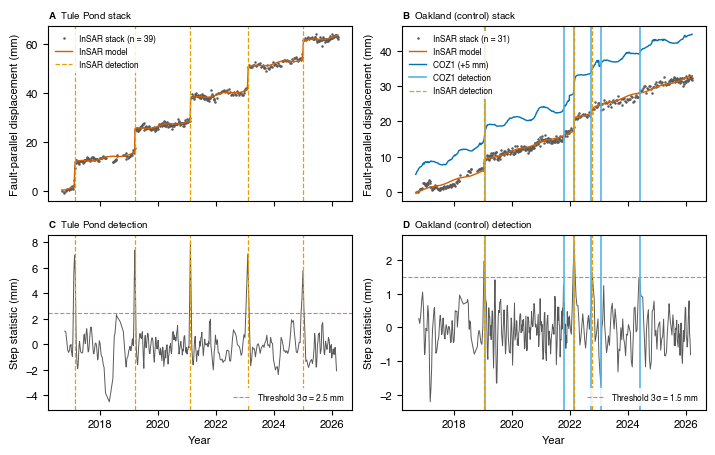

In [7]:
# [14]
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6), sharex=True)
for j, (title, key, _, _, _, cmcode) in enumerate(SEGS):
    sol = solutions[key]
    # top: the stack, the joint model, the detections
    ax = axes[0, j]
    ax.plot(sol["dates"], sol["stack"] - sol["stack"][0], ".", ms=1.6, color="0.35", label=f"InSAR stack (n = {sol['n']})")
    fitted_step_epochs = []
    for event_fit in sol["fits"]:
        fitted_step_epochs.append(event_fit["step_epoch"])
    model = np.dot(design(sol["dates"], fitted_step_epochs), sol["coef"])   # the joint model fitted above
    ax.plot(sol["dates"], model - sol["stack"][0], "-", lw=1.0, color="#D55E00", label="InSAR model")
    if sol["cm_series"] is not None:
        cm_dates, cm_slip = sol["cm_series"]
        ax.plot(cm_dates, cm_slip - cm_slip[0] + 5.0, "-", lw=1.0, color="#0072B2", label=f"{cmcode} (+5 mm)")
    for i, (detect_yr, stat) in enumerate(sol["cm_detections"]):
        ax.axvline(detect_yr, color="#56B4E9", lw=1.2, label=f"{cmcode} detection" if i == 0 else None)
    for i, (detect_yr, stat) in enumerate(sol["detections"]):
        ax.axvline(detect_yr, color="#E69F00", lw=0.9, ls="--", label="InSAR detection" if i == 0 else None)
    ax.set_ylabel("Fault-parallel displacement (mm)")
    utils.panel_title(ax, "AB"[j], f"{title} stack")
    ax.legend(fontsize=6, loc="upper left")
    # bottom: the step statistic against the threshold
    ax = axes[1, j]
    ax.axhline(k_sigma * sol["stat_sigma"], color="#CC79A7", lw=0.8, ls="--", label=f"Threshold {k_sigma:g}$\\sigma$ = {k_sigma * sol['stat_sigma']:.1f} mm")
    ax.plot(sol["stat_dates"], sol["stat_values"], "-", lw=0.7, color="0.35")
    for detect_yr, stat in sol["cm_detections"]:
        ax.axvline(detect_yr, color="#56B4E9", lw=1.2)
    for detect_yr, stat in sol["detections"]:
        ax.axvline(detect_yr, color="#E69F00", lw=0.9, ls="--")
    ax.set_ylabel("Step statistic (mm)")
    ax.set_xlabel("Year")
    utils.panel_title(ax, "CD"[j], f"{title} detection")
    ax.legend(fontsize=6, loc="lower right")
fig.tight_layout()
f_detect = os.path.join(fig_dir, f"figS_event_detection_{params}_k{k_sigma:g}_win{win_n}.png")
fig.savefig(f_detect, dpi=300)
fig.savefig(f_detect.replace(".png", ".pdf"))
print("Saved figure to:", f_detect)
plt.show()

## [15] Along strike: the joint model at every crossing

The same design (linear + annual + a step at each step epoch, held fixed) fitted
crossing by crossing. Away from its section an event's amplitude fits to
noise about zero, which is how the along-strike extent is read. The
event-driven fraction is the section's summed event slip over the total slip
in the window; it is a regression ratio and is not confined to 0 to 100%.

In [8]:
# [16]
gaussian_smooth_km = utils.gaussian_smooth_km      # NaN-aware, gap-preserving Gaussian along the fault (one definition, insar_utils)


def interp_nan(x, y):
    """Bridge NaN gaps inside the data range by linear interpolation (x must be sorted)."""
    y = np.asarray(y, float).copy()
    ok = np.isfinite(y)
    if ok.sum() >= 2:
        inner = (x >= x[ok][0]) & (x <= x[ok][-1])
        fill = inner & ~ok
        y[fill] = np.interp(x[fill], x[ok], y[ok])
    return y


# the joint model with every event of both sections, at every crossing (the step epoch of each is onset_lo)
step_epochs_all = creep_events["onset_lo"].to_numpy(float)
segment_of = creep_events["segment"].to_numpy()
design_all = design(dates, step_epochs_all)
inter_event_rate = np.full(len(lats), np.nan)
event_amp = np.full((len(step_epochs_all), len(lats)), np.nan)    # one row per event, one column per crossing
for i in range(len(lats)):
    values = fp_matrix[i]
    ok = np.isfinite(values)
    if ok.sum() < min_epoch_frac * len(dates):
        continue
    coef_i, *_ = np.linalg.lstsq(design_all[ok], values[ok], rcond=None)
    inter_event_rate[i] = coef_i[1]
    event_amp[:, i] = coef_i[4:]

# per section: summed event slip, the event-driven fraction, and the numbers near the centre
# (within the stack half-width, +/- stack_half_km along the trace, as the detection stack)
columns = {"lat": lats, "km": km, "inter_event_rate": inter_event_rate,
           "inter_event_rate_smooth": gaussian_smooth_km(inter_event_rate, km, smooth_km)}
frac_stats = {}
for title, key, fraction_column, _, _, _ in SEGS:
    in_segment = segment_of == key
    event_sum = event_amp[in_segment].sum(axis=0)
    total = inter_event_rate * span + event_sum
    fraction = 100 * event_sum / np.where(np.abs(total) > total_floor_mm, total, np.nan)
    columns[f"event_sum_{fraction_column}"] = event_sum
    columns[f"event_frac_{fraction_column}"] = fraction
    columns[f"event_frac_{fraction_column}_smooth"] = gaussian_smooth_km(fraction, km, smooth_km)
    for j in np.flatnonzero(in_segment):
        columns[f"amp_{step_epochs_all[j]:.3f}"] = event_amp[j]          # the column is named by the event's step epoch
    near_centre = np.abs(km - float(to_km([segments[key]["lat"]])[0])) <= stack_half_km + 1e-6
    fraction_valid = fraction[near_centre & np.isfinite(fraction)]
    frac_stats[key] = dict(n=int(near_centre.sum()), sum_median=float(np.nanmedian(event_sum[near_centre])), median=float(np.median(fraction_valid)),
                           p5=float(np.percentile(fraction_valid, 5)), p95=float(np.percentile(fraction_valid, 95)))
    print(f"{title}: {near_centre.sum()} crossings within the stack half-width; summed event slip median {np.nanmedian(event_sum[near_centre]):.1f} mm; "
          f"fraction median {np.median(fraction_valid):.0f}%, 5-95% {np.percentile(fraction_valid, 5):.0f} to {np.percentile(fraction_valid, 95):.0f}%")
event_fraction = pd.DataFrame(columns)
event_fraction.to_csv(os.path.join(out_dir, "event_fraction_by_crossing.csv"), index=False)

Tule Pond: 40 crossings within the stack half-width; summed event slip median 49.3 mm; fraction median 78%, 5-95% 38 to 95%
Oakland (control): 34 crossings within the stack half-width; summed event slip median 8.2 mm; fraction median 24%, 5-95% 10 to 40%


## [17] The window around the section, and the slip above the inter-event rate

Per crossing, a linear + annual model is fitted to the INTER-event epochs only,
with one step column per event so the offsets between events do not drag the
rate up (each column is 0 before the event's 6 to 12 day acquisition interval
and 1 after it; no duration is fitted). The constant + rate + annual part is
subtracted from every epoch: what is left is the cumulative slip above the
inter-event rate, the hovmoller of Fig 1. The 20 km window for everything
along strike is re-centred on the peak of that cumulative slip at the end of
the record, so it follows the data rather than the seed centre.

In [9]:
# [18]
_, _, tulepond_column, seed_centre_km, half_span_km, _ = SEGS[0]           # Tule Pond
windows = list(zip(tulepond_events["onset_lo"], tulepond_events["onset_hi"]))

# design: constant, rate, annual, plus one column per event that is 0 before its acquisition interval
# (onset_lo to onset_hi, 6 to 12 d) and 1 after it. Only the inter-event epochs are fitted, so to the fit
# each column is a plain step: it absorbs that event's offset so the staircase does not drag the rate up.
# (The linear slope inside the interval is never fitted; it only touches the excluded epochs.)
ramp_columns = [np.ones_like(dates), dates, np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
for start, end in windows:
    ramp_columns.append(np.clip((dates - start) / (end - start), 0, 1))
design_ramp = np.column_stack(ramp_columns)
min_inter_event_epochs = 10     # a crossing needs this many finite inter-event epochs
inter_event = np.ones_like(dates, dtype=bool)
for start, end in windows:
    inter_event &= ~((dates >= start) & (dates <= end))
slip_above_rate = np.full_like(fp_matrix, np.nan)
crossing_rates = np.full(fp_matrix.shape[0], np.nan)          # each crossing's own inter-event rate (mm/yr)
for i in range(fp_matrix.shape[0]):
    values = fp_matrix[i]
    ok = np.isfinite(values) & inter_event
    if ok.sum() < min_inter_event_epochs:
        continue
    coef_i = np.linalg.lstsq(design_ramp[ok], values[ok], rcond=None)[0]
    slip_above_rate[i] = values - np.dot(design_ramp[:, :4], coef_i[:4])          # only constant + rate + annual subtracted: the steps stay
    crossing_rates[i] = coef_i[1]
for j in range(slip_above_rate.shape[1]):                       # smooth each epoch along the fault
    slip_above_rate[:, j] = gaussian_smooth_km(slip_above_rate[:, j], km, smooth_km)

# re-centre the window on the peak of the cumulative slip at the end of the record
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    final_slip = np.nanmean(slip_above_rate[:, -5:], axis=1)
seed_window = (km >= seed_centre_km - half_span_km) & (km <= seed_centre_km + half_span_km)
peak_km = float(km[seed_window][np.nanargmax(final_slip[seed_window])])
window_centre_km = min(max(peak_km, km.min() + half_span_km), km.max() - half_span_km)     # kept inside the data
w_lo = window_centre_km - half_span_km
w_hi = window_centre_km + half_span_km
# the Fig 1 caption quotes the typical removed rate: the median of the per-crossing rates over the window
# (each crossing has its own rate removed; this number only describes them)
in_window_crossings = (km >= w_lo) & (km <= w_hi)
inter_event_rate_median = float(np.nanmedian(crossing_rates[in_window_crossings]))
print(f"window re-centred on the cumulative-slip peak at {peak_km:.1f} km: {w_lo:.1f} to {w_hi:.1f} km; "
      f"median of the per-crossing inter-event rates in the window {inter_event_rate_median:.2f} mm/yr "
      f"(5-95 %: {np.nanpercentile(crossing_rates[in_window_crossings], 5):.2f} to "
      f"{np.nanpercentile(crossing_rates[in_window_crossings], 95):.2f})")

window re-centred on the cumulative-slip peak at 58.6 km: 48.4 to 68.4 km; median of the per-crossing inter-event rates in the window 4.50 mm/yr (5-95 %: 0.97 to 7.42)


## [19] Section lengths (Dani's sketch, 2026-09-21)

Two lengths on the cumulative event slip profile of Tule Pond:

1. **Length of fault hosting the events**: the contiguous span around the peak
   over which the cumulative event slip (sum of the five steps, 0.4 km
   smoothed, short gaps bridged) stays above the flank noise. The threshold is
   3 robust sigma of the same profile on the flanks (52 to 56 and 64 to 68
   km), so it comes from the data. The spans above 10% and 20% of the peak
   are printed beside it as a sensitivity check. How sharp its two ends are:
   the 10-90 % edge width at each end, the along-trace distance over which the
   same profile falls from 90 % to 10 % of its peak, walking out from the peak
   north and south (linear between crossings).
2. **Width of the peak slip zone**: the contiguous run where the smoothed
   event-driven fraction is at least 75% (and, alternatively, 90%) of its
   peak. The 90% band is what the figures draw and the paper quotes.

In [10]:
# [20]
def contiguous_span(km_axis, values, threshold):
    """Span (km_lo, km_hi, n) of the contiguous run around the peak of values where values >= threshold;
    km_axis sorted."""
    peak = int(np.nanargmax(values))
    above = np.isfinite(values) & (values >= threshold)
    lo = peak
    hi = peak
    while lo > 0 and above[lo - 1]:
        lo -= 1
    while hi < len(values) - 1 and above[hi + 1]:
        hi += 1
    return float(km_axis[lo]), float(km_axis[hi]), int(hi - lo + 1)


# everything along strike from here is on the north -> south sorted axis km_sorted
in_window = (km_sorted >= w_lo) & (km_sorted <= w_hi)
cum_event_slip = interp_nan(km_sorted, gaussian_smooth_km(event_fraction[f"event_sum_{tulepond_column}"].values, km, smooth_km)[north_to_south])
cum_event_slip_window = np.where(in_window, cum_event_slip, np.nan)
on_flanks = np.zeros(len(km_sorted), bool)
for flank_lo, flank_hi in flank_km:
    on_flanks |= (km_sorted >= flank_lo) & (km_sorted <= flank_hi)
flank_sigma = utils.robust_sigma(cum_event_slip[on_flanks])
flank_median = np.nanmedian(cum_event_slip[on_flanks])
length_threshold = flank_median + 3 * flank_sigma
peak_cum = float(np.nanmax(cum_event_slip_window))
len_lo, len_hi, len_n = contiguous_span(km_sorted, cum_event_slip_window, length_threshold)
print(f"cumulative event slip: peak {peak_cum:.1f} mm at {km_sorted[np.nanargmax(cum_event_slip_window)]:.1f} km; "
      f"flanks median {flank_median:.1f} mm, robust sigma {flank_sigma:.2f} mm -> threshold {length_threshold:.1f} mm")
print(f"  length of fault hosting the events (above threshold): {len_lo:.1f} to {len_hi:.1f} km = {len_hi - len_lo:.1f} km ({len_n} crossings)")
lengths = {"threshold": (len_lo, len_hi)}
for pct in (10, 20):
    pct_lo, pct_hi, _ = contiguous_span(km_sorted, cum_event_slip_window, pct / 100 * peak_cum)
    lengths[f"{pct}pct"] = (pct_lo, pct_hi)
    print(f"  sensitivity, above {pct}% of peak: {pct_lo:.1f} to {pct_hi:.1f} km = {pct_hi - pct_lo:.1f} km")


def level_crossing_km(km_axis, values, level, step):
    """km where values first falls below level walking out from the peak (step -1: north, +1: south, on the
    north -> south axis km_axis), linear between the last crossing at or above level and the first below it."""
    i = int(np.nanargmax(values))
    while 0 <= i + step < len(values) and np.isfinite(values[i + step]) and values[i + step] >= level:
        i += step
    j = i + step
    assert 0 <= j < len(values) and np.isfinite(values[j]), f"the profile does not fall below {level:.2f} mm inside the window"
    return float(np.interp(level, [values[j], values[i]], [km_axis[j], km_axis[i]]))


edge_widths = {}                         # end -> (km at 90 %, km at 10 %, 10-90 % width km)
for end, step in (("north", -1), ("south", +1)):
    km_90 = level_crossing_km(km_sorted, cum_event_slip_window, 0.9 * peak_cum, step)
    km_10 = level_crossing_km(km_sorted, cum_event_slip_window, 0.1 * peak_cum, step)
    edge_widths[end] = (km_90, km_10, abs(km_10 - km_90))
    print(f"  {end} end: 90% of peak at {km_90:.2f} km, 10% at {km_10:.2f} km: 10-90% edge width {abs(km_10 - km_90):.2f} km")

# the peak slip zone: where the smoothed fraction stays above band_fracs x its peak
fraction_smooth = interp_nan(km_sorted, event_fraction[f"event_frac_{tulepond_column}_smooth"].values[north_to_south])
fraction_window = np.where(in_window, fraction_smooth, np.nan)
peak_frac = float(np.nanmax(fraction_window))
bands = {}
for band_frac in band_fracs:
    band_lo, band_hi, band_n = contiguous_span(km_sorted, fraction_window, band_frac * peak_frac)
    bands[band_frac] = (band_lo, band_hi, band_n)
    print(f"  peak slip zone at {100 * band_frac:.0f}% of the fraction peak ({peak_frac:.0f}%): {band_lo:.1f} to {band_hi:.1f} km = "
          f"{band_hi - band_lo:.1f} km, {band_n} crossings")

# the control: COZ1's 75% band on its own fraction, inside its seed window
_, _, _, coz1_centre_km, coz1_half_span_km, _ = SEGS[1]
coz1_band_frac = 0.75
fraction_coz1 = interp_nan(km_sorted, event_fraction["event_frac_coz1_smooth"].values[north_to_south])
in_window_coz1 = (km_sorted >= coz1_centre_km - coz1_half_span_km) & (km_sorted <= coz1_centre_km + coz1_half_span_km)
fraction_coz1_window = np.where(in_window_coz1, fraction_coz1, np.nan)
coz1_lo, coz1_hi, coz1_n = contiguous_span(km_sorted, fraction_coz1_window, coz1_band_frac * np.nanmax(fraction_coz1_window))

# the measured extents, for the map brackets (notebook 05) and the text
band_lo, band_hi, band_n = bands[band_main]
section_lengths = pd.DataFrame([
    dict(name="tulepond_creep_length", km_lo=len_lo, km_hi=len_hi, lat_lo=lat_of_km(len_hi), lat_hi=lat_of_km(len_lo), n=len_n),
    dict(name="tulepond_band75", km_lo=bands[0.75][0], km_hi=bands[0.75][1], lat_lo=lat_of_km(bands[0.75][1]), lat_hi=lat_of_km(bands[0.75][0]), n=bands[0.75][2]),
    dict(name="tulepond_band90", km_lo=bands[0.90][0], km_hi=bands[0.90][1], lat_lo=lat_of_km(bands[0.90][1]), lat_hi=lat_of_km(bands[0.90][0]), n=bands[0.90][2]),
    dict(name="oakland_band75", km_lo=coz1_lo, km_hi=coz1_hi, lat_lo=lat_of_km(coz1_hi), lat_hi=lat_of_km(coz1_lo), n=coz1_n)])
section_lengths.to_csv(os.path.join(out_dir, "section_lengths.csv"), index=False)
print("Saved section_lengths.csv")

cumulative event slip: peak 53.7 mm at 58.7 km; flanks median -0.1 mm, robust sigma 2.33 mm -> threshold 6.9 mm
  length of fault hosting the events (above threshold): 56.3 to 62.2 km = 5.9 km (59 crossings)
  sensitivity, above 10% of peak: 56.2 to 62.4 km = 6.2 km
  sensitivity, above 20% of peak: 56.6 to 62.0 km = 5.4 km
  north end: 90% of peak at 58.15 km, 10% at 56.15 km: 10-90% edge width 1.99 km
  south end: 90% of peak at 60.30 km, 10% at 62.41 km: 10-90% edge width 2.11 km
  peak slip zone at 75% of the fraction peak (88%): 57.8 to 60.5 km = 2.7 km, 28 crossings
  peak slip zone at 90% of the fraction peak (88%): 58.2 to 59.8 km = 1.6 km, 17 crossings
Saved section_lengths.csv


## [21] The band stack: the five events

Mean of the crossings inside the peak slip zone, then the joint model with
the steps at the catalogue's step epochs and block-bootstrap CIs on the steps. Done for both
band definitions; the figures draw the 90% band.
PREPUB: The draft's numbers (same code, same 0.7 stream, July 2026) are printed for comparison.

In [11]:
# [22]
def band_stack(lo_km, hi_km, step_epochs):
    """Mean series of the crossings between lo_km and hi_km, zeroed at its first finite epoch, with the
    joint fit and bootstrap CIs on the steps."""
    in_band = (km >= lo_km) & (km <= hi_km)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack_mean = np.nanmean(fp_matrix[in_band], axis=0)
        stack_std = np.nanstd(fp_matrix[in_band], axis=0)
    ok = np.isfinite(stack_mean)
    stack_mean = stack_mean - stack_mean[ok][0]
    coef, rss = fit_joint(dates[ok], stack_mean[ok], step_epochs)
    ci_lo, ci_hi = bootstrap_amplitudes(dates[ok], stack_mean[ok], step_epochs)
    return dict(n=int(in_band.sum()), mean=stack_mean, std=stack_std, coef=coef, steps=coef[4:], ci_lo=ci_lo, ci_hi=ci_hi,
                secular=float(coef[1]), annual=float(np.hypot(coef[2], coef[3])), rms=float(np.sqrt(rss / ok.sum())))


band_results = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_stack(lo_km, hi_km, step_epochs_tulepond)
    band_results[band_frac] = result
    pd.DataFrame({"t": dates, "stack_mm": result["mean"], "std_mm": result["std"]}
                 ).to_csv(os.path.join(out_dir, f"band_stack_{int(band_frac * 100)}pct.csv"), index=False)
    print(f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km, n = {result['n']} crossings; secular {result['secular']:.2f} mm/yr, "
          f"annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm")
    for step_epoch, step, ci_lo, ci_hi in zip(step_epochs_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]):
        print(f"    {step_epoch:.3f}: {step:5.2f} mm  [{ci_lo:.2f}, {ci_hi:.2f}]")
    print(f"    sum {np.sum(result['steps']):.1f} mm, mean {np.mean(result['steps']):.1f} mm, "
          f"range {np.min(result['steps']):.1f} to {np.max(result['steps']):.1f} mm")
    # does each event's 95% CI overlap the others'? one y/n per event
    overlap_lines = []
    for step_epoch, lo_1, hi_1 in zip(step_epochs_tulepond, result["ci_lo"], result["ci_hi"]):
        flags = ""
        for lo_2, hi_2 in zip(result["ci_lo"], result["ci_hi"]):
            if lo_1 <= hi_2 and lo_2 <= hi_1:
                flags += "y"
            else:
                flags += "n"
        overlap_lines.append(f"{step_epoch:.0f}:{flags}")
    print("    95% CI overlap with the others (y/n per event): " + ", ".join(overlap_lines))
    print("")
print("draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, secular 1.08 mm/yr")  # PREPUB
step_epochs_coz1 = coz1_events["onset_lo"].to_numpy(float)          # every COZ1 control event ([10])
coz1_band = band_stack(coz1_lo, coz1_hi, step_epochs_coz1)
print(f"control, Oakland 75% band {coz1_lo:.1f} to {coz1_hi:.1f} km (n = {coz1_band['n']}): steps "
      f"{np.round(coz1_band['steps'], 2).tolist()} mm, secular {coz1_band['secular']:.2f} mm/yr")

band 75%: 57.8 to 60.5 km, n = 28 crossings; secular 1.25 mm/yr, annual 0.60 mm, rms 0.93 mm
    2017.099: 10.99 mm  [9.78, 12.07]
    2019.186: 10.54 mm  [9.53, 11.54]
    2021.107: 10.56 mm  [9.61, 11.46]
    2023.080: 10.93 mm  [9.96, 11.87]
    2024.984:  7.95 mm  [7.08, 8.79]
    sum 51.0 mm, mean 10.2 mm, range 7.9 to 11.0 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyn, 2019:yyyyn, 2021:yyyyn, 2023:yyyyn, 2025:nnnny



band 90%: 58.2 to 59.8 km, n = 17 crossings; secular 0.96 mm/yr, annual 0.78 mm, rms 1.18 mm
    2017.099: 10.69 mm  [8.85, 12.18]
    2019.186: 10.47 mm  [8.99, 12.00]
    2021.107: 11.25 mm  [9.85, 12.60]
    2023.080: 11.73 mm  [10.30, 13.14]
    2024.984:  7.74 mm  [6.45, 9.01]
    sum 51.9 mm, mean 10.4 mm, range 7.7 to 11.7 mm
    95% CI overlap with the others (y/n per event): 2017:yyyyy, 2019:yyyyy, 2021:yyyyn, 2023:yyyyn, 2025:yynny

draft (July 2026, 75% band 57.7 to 60.1 km, 25 crossings): 10.84, 10.46, 10.70, 11.16, 7.67 mm, sum 50.8, secular 1.08 mm/yr
control, Oakland 75% band 32.9 to 33.6 km (n = 8): steps [3.17, 6.15, 3.75] mm, secular 2.10 mm/yr


## [23] The slip budget, the alignment arrays and the creepmeters

Per crossing: inter-event rate, the summed event steps over the record
length, and their sum, smoothed as Fig 1C (one Gaussian, sigma profile_smooth_km = 0.2 km; Dani 2026-10-03).
Each block counts the events of its own section: Fig 1C, 1D and the Tule
Pond blocks add the five Tule Pond events only; the Oakland control block
adds its own (COZ1) events, all of them (three since 2026-10-05). Both sets of
steps stay in the joint model at every crossing (cell [16]).
The alignment arrays enter twice:
refit over the InSAR window from their survey files (dark grey in Fig 1,
black in the supplement; needs 4 surveys spanning 5 yr), and the archive's
whole-record rate (grey). Creepmeter rates are over the InSAR window.

1-sigma error bars (Dani 2026-10-02, "reviewers always ask"): arrays = the
least-squares standard error of the refit, from the scatter of the surveys
about the line (the survey std's alone give a 3-10x smaller formal error:
the scatter is episodic creep, not survey error); creepmeters = the standard
error of the slip gained in each whole year (daily samples are not
independent, so the regression error, ~0.01 mm/yr, would be meaningless).

In [12]:
# [24]
# the step columns of the five Tule Pond events (cell [16] names each by its step epoch)
tulepond_amp_columns = []
for step_epoch in step_epochs_tulepond:
    column = f"amp_{step_epoch:.3f}"
    assert column in event_fraction.columns, f"no per-crossing step column {column} for the Tule Pond event"
    tulepond_amp_columns.append(column)
slip_budget = event_fraction[["lat", "km"]].copy()
slip_budget["secular"] = event_fraction["inter_event_rate"]
slip_budget["event_sum"] = event_fraction[tulepond_amp_columns].sum(axis=1, min_count=1)      # Tule Pond events only
slip_budget["event_rate"] = slip_budget["event_sum"] / span
slip_budget["total"] = slip_budget["secular"] + slip_budget["event_rate"]
# the Oakland control block counts its own events instead, all of them (each block counts the events of its own section)
coz1_amp_columns = []
for step_epoch in step_epochs_coz1:
    column = f"amp_{step_epoch:.3f}"
    assert column in event_fraction.columns, f"no per-crossing step column {column} for the Oakland event"
    coz1_amp_columns.append(column)
slip_budget["event_rate_oakland"] = event_fraction[coz1_amp_columns].sum(axis=1, min_count=1) / span
slip_budget["total_oakland"] = slip_budget["secular"] + slip_budget["event_rate_oakland"]
slip_budget = slip_budget.sort_values("km").reset_index(drop=True)
for name in ("secular", "event_rate", "total"):
    slip_budget[f"{name}_smooth"] = gaussian_smooth_km(slip_budget[name].values, slip_budget["km"].values, profile_smooth_km)   # = Fig 1C
slip_budget.to_csv(os.path.join(out_dir, "slip_budget_by_crossing.csv"), index=False)

# alignment arrays within aa_max_dist_km of the trace: refit over the InSAR window and the archive's whole-record rate
# Arrays in the summary with no survey file are named here and skipped; every other array must load
# (a missing or unreadable survey file stops the notebook). Checked 2026-10-03: none are missing.
aa_no_survey_file = []
aa_summary = utils.load_aa_summary(common_paths["aa_summary"])
aa_summary = utils.project_to_fault(aa_summary, x_fault, lon_col="long_deg", lat_col="lat_deg")
aa_rows = []
for _, site in aa_summary.iterrows():
    if abs(site.dist_fault_km) > aa_max_dist_km:
        continue
    if site.site_code in aa_no_survey_file:
        print(f"  AA {site.site_code}: no survey file (listed in aa_no_survey_file), skipped")
        continue
    array = utils.load_aa(common_paths["aa_dir"], site.site_code)
    surveys_in_window = array[(array.year >= t0) & (array.year <= t1)]
    if len(surveys_in_window) > 0:
        span_in_window = surveys_in_window.year.max() - surveys_in_window.year.min()
    else:
        span_in_window = 0.0
    if len(surveys_in_window) >= aa_min_surveys and span_in_window >= aa_min_span_yr:
        rate_window, _, rate_window_se, _ = utils.linear_rate(surveys_in_window.year.values, surveys_in_window.cum_mm.values)
    else:
        rate_window = np.nan
        rate_window_se = np.nan
    aa_rows.append(dict(code=site.site_code, name=site.site_name, lat=site.lat_deg, lon=site.long_deg, km=float(to_km([site.lat_deg])[0]),
                        rate_window=rate_window, rate_window_se=rate_window_se, n_window=len(surveys_in_window), span_window=span_in_window,
                        rate_longterm=float(site["rate_lnrr"]), first_yr=float(site["first_yr"]), last_yr=float(site["last_yr"])))
aa_rates = pd.DataFrame(aa_rows).sort_values("km")
aa_rates.to_csv(os.path.join(out_dir, "aa_rates.csv"), index=False)
print(f"{len(aa_rates)} Hayward arrays within {aa_max_dist_km:g} km of the trace; {aa_rates.rate_window.notna().sum()} refit over the InSAR window")

# creepmeter rates over the InSAR window: code -> (km, mm/yr), and their 1-sigma from the whole-year gains
cm_rates = {}
cm_rate_sigma = {}
cm_rate_rows = []
for code, lat, lon, name in creepmeters:
    cm_dates, cm_slip = utils.daily_creepmeter(common_paths["creepmeter_dir"], code, t0, t1, creepmeter_glitches)
    km_cm = float(to_km([lat])[0])
    rate_cm = utils.linear_rate(cm_dates, cm_slip)[0]
    cm_rates[code] = (km_cm, rate_cm)
    mean_gain, cm_rate_sigma[code], n_years = utils.annual_increment_rate(cm_dates, cm_slip)
    assert abs(mean_gain - rate_cm) < 0.5, f"{code}: mean yearly gain {mean_gain:.2f} vs fitted rate {rate_cm:.2f} mm/yr"
    print(f"  creepmeter {code}: {rate_cm:.2f} +/- {cm_rate_sigma[code]:.2f} mm/yr (1 sigma, {n_years} whole years; mean yearly gain {mean_gain:.2f})")
    cm_rate_rows.append(dict(code=code, km=km_cm, rate=rate_cm, rate_se=cm_rate_sigma[code]))
pd.DataFrame(cm_rate_rows).to_csv(os.path.join(out_dir, "creepmeter_rates.csv"), index=False)
in_section = aa_rates[(aa_rates.km >= len_lo - 1.0) & (aa_rates.km <= len_hi + 1.0) & aa_rates.rate_window.notna()]   # as budget_block
aa_window_text = f"{utils.decimal_year_to_day(t0).date()} to {utils.decimal_year_to_day(t1).date()}"   # the InSAR window
print(f"  arrays at Tule Pond ({len_lo - 1:.1f}-{len_hi + 1:.1f} km), refit over the InSAR window {aa_window_text}, +/- 1 sigma (mm/yr):")
assert len(in_section) > 0, "no alignment array with a window refit along the Tule Pond section"
for array_row in in_section.itertuples():
    print(f"    {array_row.code} {array_row.rate_window:.2f} +/- {array_row.rate_window_se:.2f} ({array_row.n_window} surveys)")


def budget_block(name, lo, hi, event_column="event_rate", total_column="total"):
    """Mean rates of the crossings between lo and hi km, and the arrays within 1 km of that block. The event
    columns are the Tule Pond events by default; the Oakland control block passes its own."""
    in_block = (slip_budget.km >= lo) & (slip_budget.km <= hi)
    arrays_near = aa_rates[(aa_rates.km >= lo - 1.0) & (aa_rates.km <= hi + 1.0)]
    block = dict(name=name, lo=lo, hi=hi, n=int(in_block.sum()),
                 secular=float(slip_budget.loc[in_block, "secular"].mean()), event_rate=float(slip_budget.loc[in_block, event_column].mean()),
                 total=float(slip_budget.loc[in_block, total_column].mean()),
                 frac_pct=100 * slip_budget.loc[in_block, event_column].mean() / max(slip_budget.loc[in_block, total_column].mean(), 1e-9),
                 aa_window_mean=float(arrays_near.rate_window.mean()), aa_window_n=int(arrays_near.rate_window.notna().sum()),
                 aa_longterm_mean=float(arrays_near.rate_longterm.mean()), aa_n=len(arrays_near))
    print(f"[{name}] {lo:.1f} to {hi:.1f} km, n = {block['n']}: secular {block['secular']:.2f}, event-driven {block['event_rate']:.2f}, "
          f"total {block['total']:.2f} mm/yr ({block['frac_pct']:.0f}% event-driven); arrays: window {block['aa_window_mean']:.2f} "
          f"(n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']}) mm/yr")
    return block


budget = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    budget[f"band{int(band_frac * 100)}"] = budget_block(f"Tule Pond {100 * band_frac:.0f}% band", lo_km, hi_km)
budget["length"] = budget_block("Tule Pond, length hosting events", len_lo, len_hi)
budget["flanks"] = budget_block("Tule Pond band +/- 5 km (band included)", band_lo - 5.0, band_hi + 5.0)   # key name kept for the registry
budget["coz1"] = budget_block(f"Oakland control 75% band (its own {len(step_epochs_coz1)} events)", coz1_lo, coz1_hi,
                              event_column="event_rate_oakland", total_column="total_oakland")

  AA HAPP: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1995.007 vs 1/28/1995, 1996.820 vs 10/22/1996, 2024.680 vs 10/5/2024; 0 without a readable date
  AA HCCD: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2023.841 vs 12/3/2023; 0 without a readable date
  AA HDST: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1988.563 vs 6/24/1988; 0 without a readable date
  AA HDWT: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2015.721 vs 10/20/2015, 2017.782 vs 10/14/2017, 2018.782 vs 10/14/2018; 0 without a readable date
  AA HFLO: 2 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2017.782 vs 10/14/2017, 2018.782 vs 10/14/2018; 0 without a readable date
  AA HFMT: 13 

33 Hayward arrays within 2 km of the trace; 30 refit over the InSAR window


  CPP1: 2 listed glitch days dropped of 3420: 2017-05-18 to 2017-05-18 (1 d: two 10-min samples at -283.7 mm (~340 mm below the record) pull the daily mean down 4.8 mm); 2018-02-12 to 2018-02-12 (1 d: one 10-min sample at -283.7 mm (~350 mm below the record) pulls the daily mean down 2.4 mm)
  creepmeter CPP1: 5.05 +/- 0.37 mm/yr (1 sigma, 9 whole years; mean yearly gain 5.22)


  CTM1: 0 listed glitch days dropped of 3225
  creepmeter CTM1: 4.11 +/- 0.22 mm/yr (1 sigma, 9 whole years; mean yearly gain 4.13)


  COZ1: 0 listed glitch days dropped of 3484
  creepmeter COZ1: 4.43 +/- 1.01 mm/yr (1 sigma, 9 whole years; mean yearly gain 4.14)


  CHP1: 0 listed glitch days dropped of 3353
  creepmeter CHP1: 3.81 +/- 0.08 mm/yr (1 sigma, 9 whole years; mean yearly gain 3.81)


  CFW1: 0 listed glitch days dropped of 3437
  creepmeter CFW1: 6.99 +/- 0.73 mm/yr (1 sigma, 9 whole years; mean yearly gain 6.99)
  arrays at Tule Pond (55.3-63.2 km), refit over the InSAR window 2016-09-03 to 2026-03-21, +/- 1 sigma (mm/yr):
    HGIL 6.88 +/- 0.55 (8 surveys)
    HRKT 6.96 +/- 0.37 (9 surveys)
    HHAN 6.81 +/- 0.18 (8 surveys)
    HUNI 7.20 +/- 0.35 (8 surveys)
[Tule Pond 75% band] 57.8 to 60.5 km, n = 28: secular 1.17, event-driven 5.41, total 6.57 mm/yr (82% event-driven); arrays: window 6.92 (n 2), long-term 5.86 (n 2) mm/yr
[Tule Pond 90% band] 58.2 to 59.8 km, n = 17: secular 0.88, event-driven 5.56, total 6.44 mm/yr (86% event-driven); arrays: window 6.88 (n 1), long-term 6.08 (n 1) mm/yr
[Tule Pond, length hosting events] 56.3 to 62.2 km, n = 59: secular 2.73, event-driven 3.71, total 6.44 mm/yr (58% event-driven); arrays: window 6.96 (n 4), long-term 6.32 (n 4) mm/yr
[Tule Pond band +/- 5 km (band included)] 53.2 to 64.8 km, n = 107: secular 4.05, event-dri

## [25] Seismicity near the section

Seismicity is Bo Xie's GrowClust relocated catalogue (relocated plus
unrelocated NCSS events); repeaters are Taira GEN3 plus Waldhauser and
Schaff; both within 2 km of the trace and inside the InSAR window.

The counts the discussion quotes (registered): earthquakes (all, and the relocated ones,
`source == "growclust"`) and repeating earthquakes within `seis_max_dist_km` of the trace,
from the first to the last InSAR acquisition (`t0`, `t1`), along strike (the km of the nearest
trace vertex) inside (a) the section hosting the events (`len_lo` to `len_hi`, the creep length of
[21]) and (b) the paper's peak-slip band (`band_main`, 90 %). The two repeater catalogues are
counted separately as well as together: they overlap in time (Waldhauser and Schaff to their end
year, Taira GEN3 to 2025) and may list the same earthquake, so the sum is an upper bound.

In [13]:
# [26]
seis = utils.load_growclust_catalog(common_paths["growclust_cat"], bbox=common_paths["aoi_bbox"])
seis = utils.project_to_fault(seis, x_fault)
seis = seis[(seis.dist_fault_km.abs() <= seis_max_dist_km) & (seis.YYYY >= t0) & (seis.YYYY <= t1)].copy()
seis["km"] = to_km(seis["ft_lat"].values)

cre = pd.concat([utils.load_cre_taira(common_paths["CRE_Taira"]), utils.load_cre_waldhauser(common_paths["CRE_Wald"])], ignore_index=True)
cre = cre.dropna(subset=["YYYY", "Lon", "Lat", "Mag"])
west, south, east, north = common_paths["aoi_bbox"]
cre = cre[(cre.Lon >= west) & (cre.Lon <= east) & (cre.Lat >= south) & (cre.Lat <= north)]
cre = utils.project_to_fault(cre, x_fault)
cre = cre[(cre.dist_fault_km.abs() <= seis_max_dist_km) & (cre.YYYY >= t0) & (cre.YYYY <= t1)].copy()
cre["km"] = to_km(cre["ft_lat"].values)

seis_window = seis[(seis.km >= w_lo) & (seis.km <= w_hi)]
cre_window = cre[(cre.km >= w_lo) & (cre.km <= w_hi)]
n_seis_win = len(seis_window)
n_cre_win = len(cre_window)
n_cre_band = int(((cre.km >= band_lo) & (cre.km <= band_hi)).sum())
print(f"within {seis_max_dist_km:g} km of the trace, {t0:.1f} to {t1:.1f}: {len(seis)} earthquakes ({(seis.source == 'growclust').sum()} relocated) "
      f"and {len(cre)} repeaters on the whole fault; in the Tule Pond window ({w_lo:.0f} to {w_hi:.0f} km): {n_seis_win} earthquakes, "
      f"{n_cre_win} repeaters; in the {100 * band_main:.0f}% band: {n_cre_band} repeaters")

# the counts the discussion quotes: the section hosting the events and the paper's band, over the InSAR period
band_tag = f"band{int(round(100 * band_main))}"                    # 'band90', as the other 04 keys
seis_count_spans = {"section": (len_lo, len_hi), band_tag: (band_lo, band_hi)}
seis_counts = {}                                                    # (span, quantity) -> count
for span_name, (span_lo, span_hi) in seis_count_spans.items():
    seis_in = seis[(seis.km >= span_lo) & (seis.km <= span_hi)]
    cre_in = cre[(cre.km >= span_lo) & (cre.km <= span_hi)]
    seis_counts[(span_name, "seis_all")] = len(seis_in)
    seis_counts[(span_name, "seis_reloc")] = int((seis_in.source == "growclust").sum())
    seis_counts[(span_name, "cre_all")] = len(cre_in)
    seis_counts[(span_name, "cre_taira")] = int((cre_in.cat == "Taira26").sum())
    seis_counts[(span_name, "cre_wald")] = int((cre_in.cat == "Waldhauser21").sum())
    assert seis_counts[(span_name, "cre_taira")] + seis_counts[(span_name, "cre_wald")] == len(cre_in), "a repeater of neither catalogue"
assert seis_counts[(band_tag, "cre_all")] == n_cre_band, "the band count differs from the one registered as 04_n_cre_band"
catalogue_spans = (f"GrowClust {seis.YYYY.min():.2f}-{seis.YYYY.max():.2f}" if len(seis) else "GrowClust: none in the window",
                   f"repeaters " + ", ".join(f"{name} {grp.YYYY.min():.2f}-{grp.YYYY.max():.2f}" for name, grp in cre.groupby("cat")))
seis_count_lines = []
for span_name, (span_lo, span_hi) in seis_count_spans.items():
    seis_count_lines.append(f"{span_name} ({span_lo:.1f}-{span_hi:.1f} km), within {seis_max_dist_km:g} km of the trace, {t0:.2f}-{t1:.2f}: "
                            f"{seis_counts[(span_name, 'seis_all')]} earthquakes ({seis_counts[(span_name, 'seis_reloc')]} relocated), "
                            f"{seis_counts[(span_name, 'cre_all')]} repeating earthquakes (Taira GEN3 {seis_counts[(span_name, 'cre_taira')]}, "
                            f"Waldhauser and Schaff {seis_counts[(span_name, 'cre_wald')]}; may overlap)")
print("\n".join(seis_count_lines))
print("events in the window by catalogue span: " + "; ".join(catalogue_spans))

within 2 km of the trace, 2016.7 to 2026.2: 1937 earthquakes (1670 relocated) and 145 repeaters on the whole fault; in the Tule Pond window (48 to 68 km): 231 earthquakes, 17 repeaters; in the 90% band: 0 repeaters
section (56.3-62.2 km), within 2 km of the trace, 2016.67-2026.22: 57 earthquakes (42 relocated), 4 repeating earthquakes (Taira GEN3 4, Waldhauser and Schaff 0; may overlap)
band90 (58.2-59.8 km), within 2 km of the trace, 2016.67-2026.22: 10 earthquakes (8 relocated), 0 repeating earthquakes (Taira GEN3 0, Waldhauser and Schaff 0; may overlap)
events in the window by catalogue span: GrowClust 2016.67-2025.99; repeaters Taira26 2016.90-2025.98


## [27] Figure 1 data: the rotated map, the hovmoller, the per-event profiles

The map is fault-parallel velocity (notebook 02) looked up on a lon/lat grid
and referenced, for DISPLAY only, to the CTM1-COZ1 patch so the fault sits at
zero. The hovmoller is the slip above the inter-event rate on a regular 6-day
grid (GMT grids must be regular). The per-event profiles are the cumulative
sum of the five fitted steps along strike.

In [14]:
# [28]
# --- the strike frame of the map: u along the mean strike from Point Pinole (km, + south), v across the fault (km, + east)
with h5py.File(map_file, "r") as hf:
    fp_map = hf["fp_velocity"][:].astype(float)
    attrs = {}
    for attr_name, attr_value in hf.attrs.items():
        if isinstance(attr_value, bytes):
            attrs[attr_name] = attr_value.decode()
        else:
            attrs[attr_name] = str(attr_value)
fp_map[fp_map == 0] = np.nan
frame = utils.strike_frame(int(attrs["EPSG"]), strike_map, x_fault["ft_lon"].values, x_fault["ft_lat"].values)   # u along strike from Point Pinole, v across

# The map is drawn by utils.fault_map_panel (the same panel as the 05 and 09 supplements): GMT's oblique
# Mercator, x axis along strike_map - 90 (north-east, across the fault), so the fault runs up the page with
# north at the top. The region is the rectangle of the strike frame utils.fault_map_corners gives: u from
# -3 km (north of Point Pinole) to 70 km (just south of CFW1), v +/- 10.9 km. Every point is plotted in
# lon/lat, no hand rotation.
_, _, corners = utils.fault_map_corners(frame)                    # (lon, lat) of the four map corners

# --- a) the FP velocity on a regular lon/lat grid (nearest UTM pixel), referenced in the strike frame
lon_axis, lat_axis, fp_lonlat = utils.utm_grid_to_lonlat(fp_map, float(attrs["X_FIRST"]), float(attrs["X_STEP"]),
                                                         float(attrs["Y_FIRST"]), float(attrs["Y_STEP"]), frame["to_utm"], corners)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
u_grid, v_grid = utils.to_uv(frame, lon_grid, lat_grid)                    # strike-frame coordinates of the grid nodes
# creepmeter positions along u: the instruments sit on the trace to within a few tens of metres (printed)
u_creepmeter, creepmeter_offset_m = utils.creepmeter_u_km(frame, x_fault["ft_lon"].values, x_fault["ft_lat"].values, creepmeters)
for code, distance_m in creepmeter_offset_m.items():
    print(f"  {code}: {distance_m:.0f} m from the nearest trace vertex")
patch_lo, patch_hi = sorted([u_creepmeter["CTM1"], u_creepmeter["COZ1"]])
# display reference: the mid-point of the two blocks' medians in the CTM1-COZ1 patch, so the
# fault sits at zero and the colour scale swings equally blue (west) and red (east)
in_patch = (u_grid >= patch_lo) & (u_grid <= patch_hi)
fp_west = np.nanmedian(fp_lonlat[in_patch & (v_grid < 0) & (v_grid >= -ref_patch_km)])
fp_east = np.nanmedian(fp_lonlat[in_patch & (v_grid > 0) & (v_grid <= ref_patch_km)])
fp_lonlat = fp_lonlat - 0.5 * (fp_west + fp_east)
vel_lim = 4.0           # colour range +/- this (mm/yr); the block medians are ~ +/- 2.5 to 3
print(f"map display reference: west block {fp_west:+.2f}, east block {fp_east:+.2f} mm/yr; mid-point removed")
grid_ll = xr.DataArray(fp_lonlat, coords={"lat": lat_axis, "lon": lon_axis}, dims=("lat", "lon"))

# --- b) the hovmoller: the slip above the inter-event rate in the window, on a regular 6-day time grid
in_window_rows = (km >= w_lo) & (km <= w_hi)
south_to_north = np.argsort(km[in_window_rows])
grid = np.arange(w_lo, w_hi + 0.05, 0.1)                                         # 100 m rows
hov_rows = np.full((grid.size, slip_above_rate.shape[1]), np.nan)
grid_index = np.round((km[in_window_rows][south_to_north] - grid[0]) / 0.1).astype(int)
on_grid = (grid_index >= 0) & (grid_index < grid.size)
hov_rows[grid_index[on_grid]] = slip_above_rate[in_window_rows][south_to_north][on_grid]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    vmax = max(float(np.nanpercentile(slip_above_rate[in_window_rows], 99.5)), 1.0)
vmin = -neg_floor_frac * vmax
t_regular = np.arange(t0, t1 + 1e-9, 6.0 / 365.25)
nearest_epoch = np.zeros(t_regular.size, int)                                    # the real epoch nearest each 6-day node
for node, t_node in enumerate(t_regular):
    nearest_epoch[node] = int(np.argmin(np.abs(dates - t_node)))
hovmoller = hov_rows[:, nearest_epoch]
hovmoller[:, np.abs(t_regular - dates[nearest_epoch]) > 9.0 / 365.25] = np.nan     # no real epoch within 9 d: blank
grid_hov = xr.DataArray(hovmoller, coords={"y": grid, "x": t_regular}, dims=("y", "x"))

# --- c) per-event cumulative slip profiles along strike, from the joint fit at every window crossing
window_rows = np.where(in_window_rows)[0][south_to_north]
km_window = km[in_window_rows][south_to_north]
design_events = design(dates, step_epochs_tulepond)
event_amp_window = np.full((window_rows.size, step_epochs_tulepond.size), np.nan)
for i, row in enumerate(window_rows):
    ok = np.isfinite(fp_matrix[row])
    if ok.sum() > design_events.shape[1] + 10:
        coef_i, *_ = np.linalg.lstsq(design_events[ok], fp_matrix[row][ok], rcond=None)
        event_amp_window[i] = coef_i[4:]
cum_prof = np.zeros((step_epochs_tulepond.size, window_rows.size))
running = np.zeros(window_rows.size)
for i in range(step_epochs_tulepond.size):
    running = running + np.nan_to_num(interp_nan(km_window, gaussian_smooth_km(event_amp_window[:, i], km_window, profile_smooth_km)))
    cum_prof[i] = running

# --- the band stack's model, split into inter-event (bluish green) and event (orange) epochs for panel E
band_main_stack = band_results[band_main]
model_full = np.dot(design(dates, step_epochs_tulepond), band_main_stack["coef"])
is_event_epoch = np.zeros(dates.size, bool)
for step_epoch in step_epochs_tulepond:
    j = int(np.searchsorted(dates, step_epoch))
    if 0 < j < dates.size:
        is_event_epoch[j] = True
event_epochs_wide = is_event_epoch.copy()
event_epochs_wide[1:] |= is_event_epoch[:-1]
event_epochs_wide[:-1] |= is_event_epoch[1:]

  CPP1: 39 m from the nearest trace vertex
  CTM1: 14 m from the nearest trace vertex
  COZ1: 56 m from the nearest trace vertex
  CHP1: 44 m from the nearest trace vertex
  CFW1: 26 m from the nearest trace vertex
map display reference: west block +1.31, east block +5.79 mm/yr; mid-point removed


## [29] Figure 1 (all pygmt, one font)

A) Map: fault-parallel velocity (notebook 02) on a page rotated to the mean
strike; creepmeters as gold triangles (as in D), city labels, a distance axis
down the left edge; the bracket is the measured length of fault hosting the
events. B) Tule Pond, slip above each crossing's own inter-event rate at every
crossing in the window, with the relocated seismicity (circles, depth colour,
size by magnitude) and the repeaters (white squares); dashed lines at the
band. C) Cumulative slip per event along strike (blues, light to dark in time).
D) Creep rates: inter-event (bluish green), event-driven (orange: the five Tule Pond events), their sum (black);
creepmeters over the InSAR window (gold), alignment arrays refit over the same
window (dark grey); error bars +/- 1 sigma. E) InSAR stack: the plain mean of
the fault-parallel series of the band crossings, zeroed at the first epoch,
nothing subtracted; the joint model (bluish green between events, orange across the
steps) is drawn over it. Colours are Okabe-Ito (bluish green against orange; Dani 2026-10-03:
the blue model line did not show against the black stack).

map panel 2.85 x 9.20 cm at true scale


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


psconvert [WARNING]: The -N+g or -N+p options do not support the -!


Saved Fig 1 to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/fig1_tulepond_ap30-150m_coh0.7_mp5_sw200m_band90.png


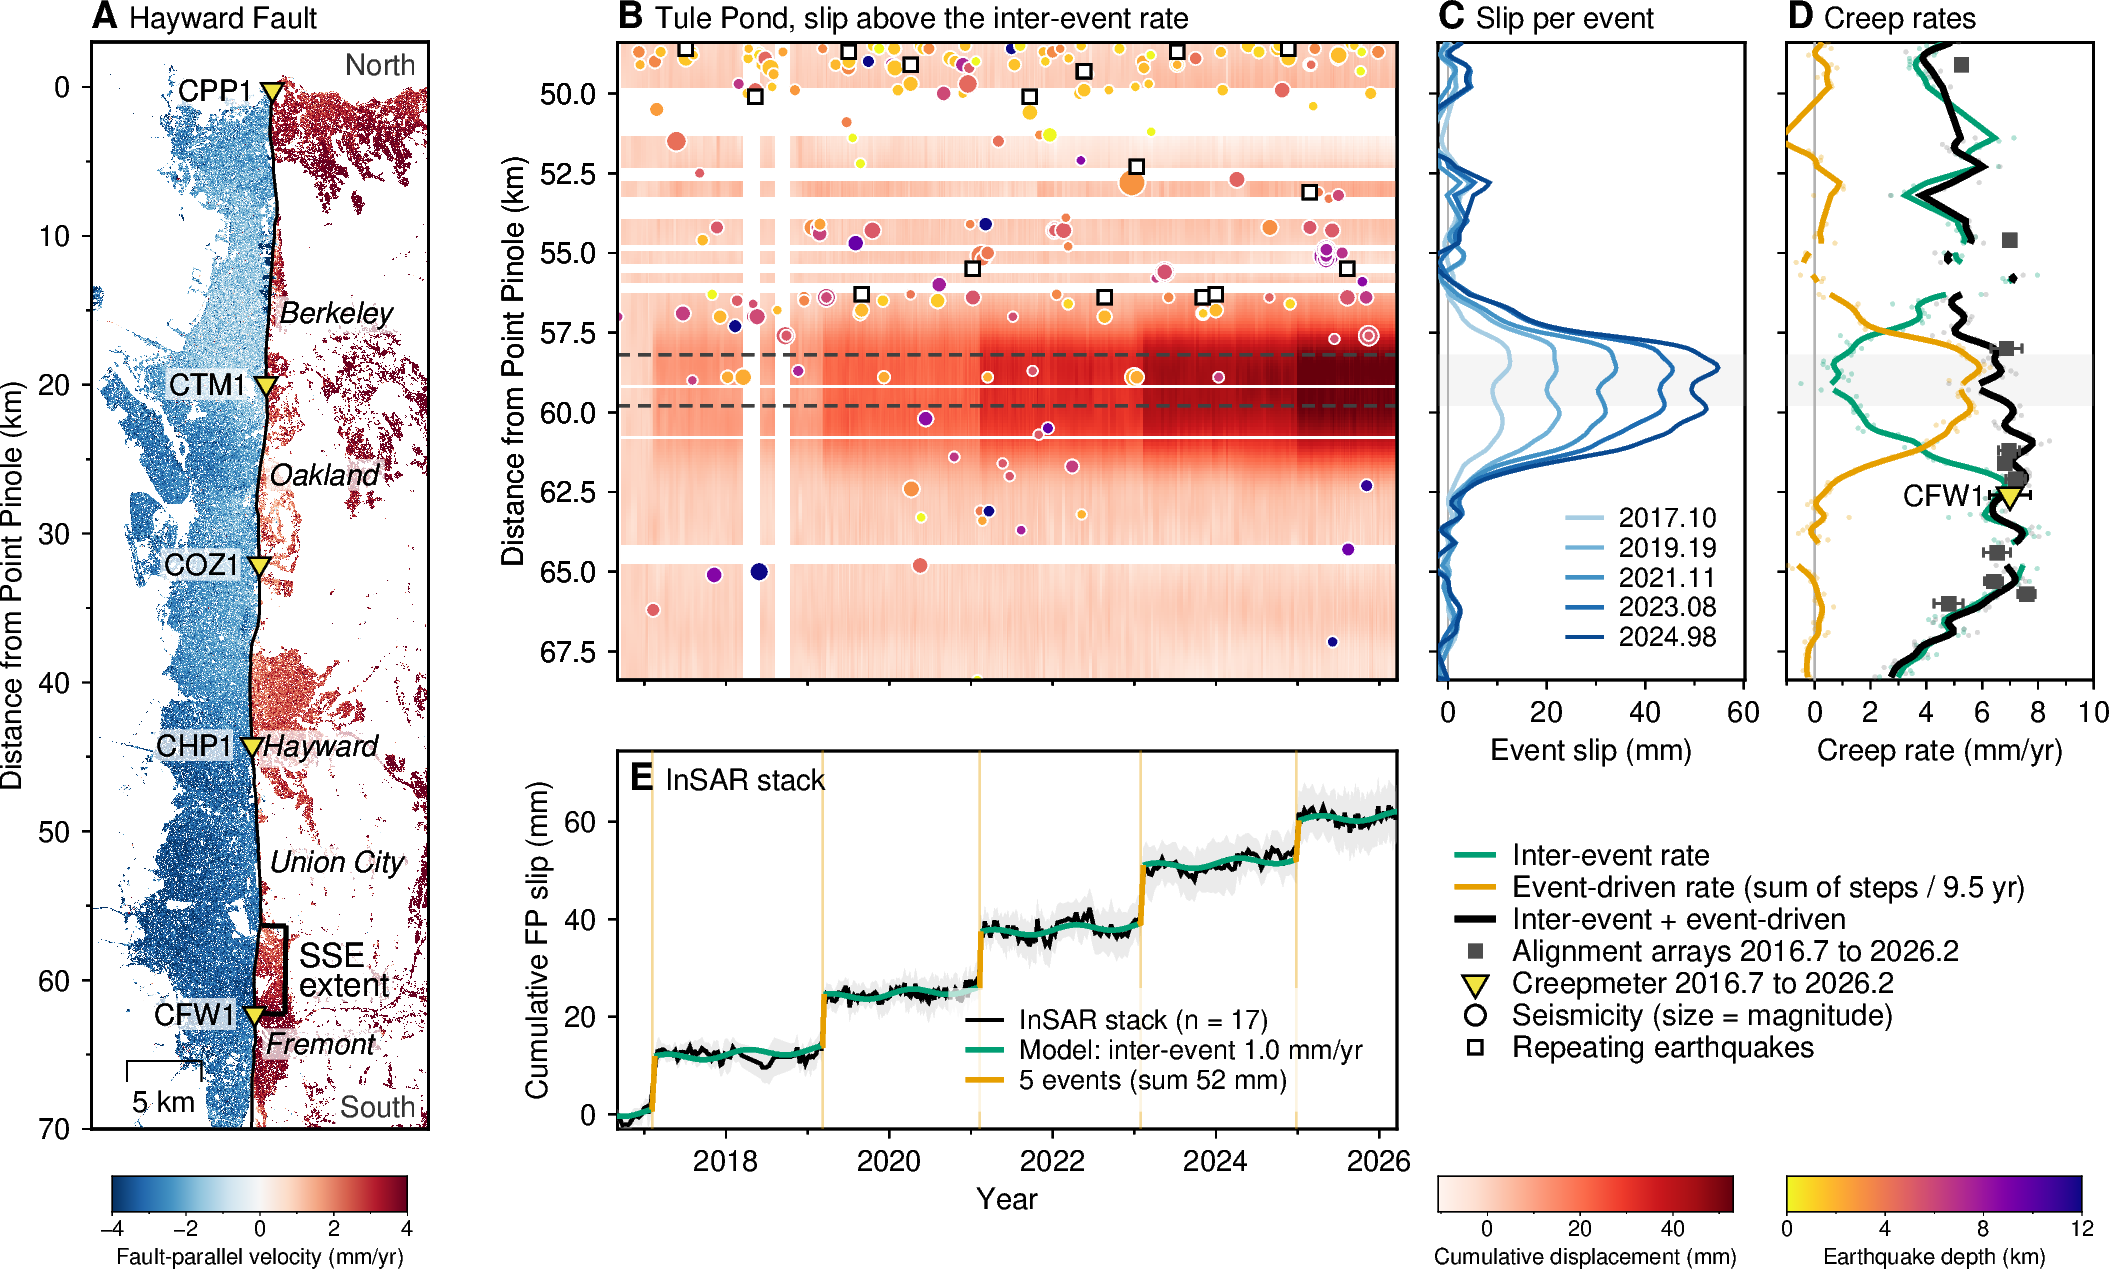

In [15]:
# [30]
# --- sizes in cm, double-column width, one font ---
green = "#009E73"                                # Okabe-Ito bluish green: inter-event rate (Dani 2026-10-03: blue does not show on the black stack)
orange = "#E69F00"                               # Okabe-Ito orange: event-driven
gold = "#F0E442"                                 # Okabe-Ito yellow: creepmeters
hov_w, hov_h = 6.6, 5.4                          # hovmoller (6.6 cm keeps the page at the 18.3 cm Science full width)
stack_h = 3.2                                    # stack: shorter than the hovmoller, so B carries the figure
gap_stack = 0.6                                  # between B and E (B has no x annotation, E has its label inside)
map_h = hov_h + gap_stack + stack_h               # map: as tall as B + gap + E, so the tops and bottoms line up (its width follows, true scale)
profile_w, rates_w, profile_h = 2.6, 2.6, hov_h  # profiles and rates panels: the same width
gap_map, gap_p, gap_r = 1.6, 0.35, 0.35          # B, C and D share one y axis, so the gaps are just the tick length
cb_w = 2.5                                       # every colour bar the same size and font (14p trick -> 7 pt)
cpt_dir = os.path.join(out_dir, "cpt")
os.makedirs(cpt_dir, exist_ok=True)
cpt_vel = utils.write_cpt(os.path.join(cpt_dir, "vel_vik.cpt"), "RdBu_r", -vel_lim, vel_lim)
cpt_hov = utils.write_cpt(os.path.join(cpt_dir, "hov_reds.cpt"), "Reds", vmin, vmax)
cpt_dep = utils.write_cpt(os.path.join(cpt_dir, "depth_plasma_r.cpt"), "plasma_r", 0, 12)

fig = pygmt.Figure()
pygmt.config(FONT="8p,Helvetica", FONT_ANNOT_PRIMARY="7p,Helvetica", FONT_LABEL="7p,Helvetica", FONT_TITLE="9p,Helvetica-Bold",
             MAP_FRAME_TYPE="plain", MAP_FRAME_PEN="0.6p", MAP_TICK_LENGTH_PRIMARY="2p", MAP_LABEL_OFFSET="4p", MAP_ANNOT_OFFSET="3p")

# A) the map: the shared rotated fault map (utils.fault_map_panel, also the 05 and 09 supplements): oblique
# Mercator, fault up the page, north at the top, true scale, map_h tall. The bracket spans the Tule Pond creep
# LENGTH (len_lo-len_hi, the 6 km of fault hosting the events, the number the paper quotes; section_lengths.csv),
# not the narrower stacked band, which stays as the dashed lines in B; labelled "SSE extent" (Dani 2026-09-29:
# it is the length that slips in the events, not the width of B). The cities, creepmeter triangles on top of
# every label (Dani 2026-10-01) and the distance axis are drawn by the same function.
map_w = utils.fault_map_panel(fig, frame, grid_ll, cpt_vel, map_h, x_fault["ft_lon"].values, x_fault["ft_lat"].values,
                              creepmeters, (len_lo, len_hi), letter="A", title="Hayward Fault",
                              colorbar_frame="xa2f1+lFault-parallel velocity (mm/yr)")

# B) hovmoller, top of the middle column
fig.shift_origin(xshift=f"{map_w + gap_map}c", yshift=f"{map_h - hov_h}c")
region_hov = [t0, t1, w_lo, w_hi]
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])
fig.grdimage(grid=grid_hov, cmap=cpt_hov, nan_transparent=True)
fig.plot(x=seis_window.YYYY.values, y=seis_window.km.values, style="c", size=0.09 + 0.05 * np.clip(seis_window.Mag.values, 0, 5),
         fill=seis_window.Depth.values, cmap=cpt_dep, pen="0.3p,white")
fig.plot(x=cre_window.YYYY.values, y=cre_window.km.values, style="s0.16c", fill="white", pen="0.6p,black")
for band_edge_km in (band_lo, band_hi):
    fig.plot(x=[t0, t1], y=[band_edge_km, band_edge_km], pen="0.7p,gray25,3_2")
fig.text(x=t0, y=w_lo, text="@%Helvetica-Bold%B@%% @:7p:Tule Pond, slip above the inter-event rate@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
fig.basemap(region=region_hov, projection=f"X{hov_w}c/-{hov_h}c", frame=["WStr", "xf1", "ya2.5+lDistance from Point Pinole (km)"])   # frame on top: a clean edge

# E) the stack, bottom of the middle column, bottom aligned with the map
fig.shift_origin(yshift=f"-{stack_h + gap_stack}c")
ok_stack = np.isfinite(band_main_stack["mean"])
region_stack = [t0, t1, -3, float(np.nanmax(band_main_stack["mean"] + band_main_stack["std"])) * 1.08]
fig.basemap(region=region_stack, projection=f"X{hov_w}c/{stack_h}c", frame=["WStr", "xa2f1+lYear", "ya20+lCumulative FP slip (mm)"])
envelope_x = np.r_[dates[ok_stack], dates[ok_stack][::-1]]
envelope_y = np.r_[(band_main_stack["mean"] + band_main_stack["std"])[ok_stack], (band_main_stack["mean"] - band_main_stack["std"])[ok_stack][::-1]]
fig.plot(x=envelope_x, y=envelope_y, fill="gray@70", close=True)
for step_epoch in step_epochs_tulepond:
    fig.plot(x=[step_epoch, step_epoch], y=[region_stack[2], region_stack[3]], pen="0.5p," + orange + "@60")
fig.plot(x=dates[ok_stack], y=band_main_stack["mean"][ok_stack], pen="0.9p,black", label=f"InSAR stack (n = {band_main_stack['n']})")
fig.plot(x=dates, y=np.where(is_event_epoch, np.nan, model_full), pen="1.2p," + green, label=f"Model: inter-event {band_main_stack['secular']:.1f} mm/yr")
fig.plot(x=dates, y=np.where(event_epochs_wide, model_full, np.nan), pen="1.2p," + orange,
         label=f"{step_epochs_tulepond.size} events (sum {np.sum(band_main_stack['steps']):.0f} mm)")
fig.text(position="TL", text="@%Helvetica-Bold%E@%% @:7p:InSAR stack@::", font="9p,Helvetica", offset="0.1c/-0.1c")
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.15c/0.15c", box="+gwhite@30")

# C) cumulative slip per event, right of the hovmoller
fig.shift_origin(xshift=f"{hov_w + gap_p}c", yshift=f"{stack_h + gap_stack}c")
xmax_profile = float(np.nanmax(cum_prof)) * 1.1
fig.basemap(region=[-2, xmax_profile, w_lo, w_hi], projection=f"X{profile_w}c/-{profile_h}c", frame=["wStr", "xa20f10+lEvent slip (mm)", "ya2.5"])
fig.plot(x=[-2, xmax_profile, xmax_profile, -2], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
blues = plt.get_cmap("Blues")                       # C: the five events, light (first) to dark (last)
n_profiles = step_epochs_tulepond.size
for i, step_epoch in enumerate(step_epochs_tulepond):
    colour = "/".join(str(int(255 * v)) for v in blues(0.35 + 0.55 * i / (n_profiles - 1))[:3])    # GMT r/g/b
    fig.plot(x=cum_prof[i], y=km_window, pen=f"0.9p,{colour}", label=f"{step_epoch:.2f}")      # each event labelled by its step epoch
fig.text(x=-2, y=w_lo, text="@%Helvetica-Bold%C@%% @:7p:Slip per event@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
with pygmt.config(FONT_ANNOT_PRIMARY="6.5p"):
    fig.legend(position="JBR+jBR+o0.1c/0.1c", box=False)

# D) creep rates: its y axis is shared with B, so no annotation
fig.shift_origin(xshift=f"{profile_w + gap_r}c")
in_window_budget = (slip_budget.km >= w_lo) & (slip_budget.km <= w_hi)
fig.basemap(region=[-1, 10, w_lo, w_hi], projection=f"X{rates_w}c/-{profile_h}c", frame=["wStr", "xa2f1+lCreep rate (mm/yr)", "ya2.5"])
fig.plot(x=[-1, 10, 10, -1], y=[band_lo, band_lo, band_hi, band_hi], fill="gray@85", close=True)
fig.plot(x=[0, 0], y=[w_lo, w_hi], pen="0.4p,gray70")
fig.plot(x=slip_budget.secular[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill=green + "@70")
fig.plot(x=slip_budget.event_rate[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill=orange + "@70")
fig.plot(x=slip_budget.total[in_window_budget].values, y=slip_budget.km[in_window_budget].values, style="c0.04c", fill="gray50@70")
fig.plot(x=slip_budget.secular_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.2p," + green, label="Inter-event rate")
fig.plot(x=slip_budget.event_rate_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.2p," + orange,
         label=f"Event-driven rate (sum of steps / {span:.1f} yr)")
fig.plot(x=slip_budget.total_smooth[in_window_budget].values, y=slip_budget.km[in_window_budget].values, pen="1.5p,black", label="Inter-event + event-driven")
arrays_window = aa_rates[(aa_rates.km >= w_lo) & (aa_rates.km <= w_hi)]
arrays_refit = arrays_window[arrays_window.rate_window.notna()]
aa_grey = "gray30"                                                    # dark grey (Dani 2026-10-02): reads apart from the black total
fig.plot(data=np.column_stack([arrays_refit.rate_window.values, arrays_refit.km.values, arrays_refit.rate_window_se.values]),
         error_bar="x+p0.6p," + aa_grey + "+w0.08c", style="s0.16c", fill=aa_grey, pen="0.3p," + aa_grey,
         label=f"Alignment arrays {t0:.1f} to {t1:.1f}")                   # +/- 1 sigma
creepmeter_legend_done = False                                        # one legend entry for the creepmeters
for code, (km_cm, rate_cm) in cm_rates.items():
    if w_lo <= km_cm <= w_hi:
        if creepmeter_legend_done:
            legend_label = None
        else:
            legend_label = f"Creepmeter {t0:.1f} to {t1:.1f}"
            creepmeter_legend_done = True
        fig.plot(data=[[rate_cm, km_cm, cm_rate_sigma[code]]], error_bar="x+p0.6p,black+w0.08c", style="i0.25c", fill=gold, pen="0.5p,black",
                 label=legend_label)                                                                             # +/- 1 sigma
        fig.text(x=rate_cm, y=km_cm, text=code, justify="RM", offset="-0.2c/0c", font="7p", no_clip=True)
fig.text(x=-1, y=w_lo, text="@%Helvetica-Bold%D@%% @:7p:Creep rates@::", justify="BL", offset="0c/0.12c", font="9p,Helvetica", no_clip=True)
# legend entries for the symbols drawn in B: plotted off-region (clipped), so only the legend records them
fig.plot(x=[-50], y=[w_lo], style="c0.17c", pen="0.6p,black", label="Seismicity (size = magnitude)")
fig.plot(x=[-50], y=[w_lo], style="s0.16c", fill="white", pen="0.6p,black", label="Repeating earthquakes")
# the legend of D in the free space under C and D
left_of_C = profile_w + gap_r                                          # from D's origin back to C's left edge
with pygmt.config(FONT_ANNOT_PRIMARY="7p"):                          # clear of the axis labels above it
    fig.legend(position=f"JBL+jTL+o-{left_of_C}c/1.2c+w{left_of_C + rates_w}c", box=False)
# the two colour bars of B, side by side, on the same line as the map's bar (0.4 cm below the map bottom)
cb_y = gap_stack + stack_h + 0.4
with pygmt.config(FONT_ANNOT_PRIMARY="13p", FONT_LABEL="13p"):          # -> ~6.5 pt at this bar thickness, as A's
    fig.colorbar(cmap=cpt_hov, position=f"x-{left_of_C}c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa20f10+lCumulative displacement (mm)")
    fig.colorbar(cmap=cpt_dep, position=f"x0c/-{cb_y:.2f}c+w{cb_w}c/0.3c+h+jTL", frame="xa4f2+lEarthquake depth (km)")

f_fig1 = os.path.join(fig_dir, f"fig1_tulepond_{params}_band{int(band_main * 100)}")
fig.savefig(f_fig1 + ".png", dpi=600, transparent=False, crop="+gwhite", anti_alias=True, show=False)   # +gwhite: opaque page
fig.savefig(f_fig1 + ".pdf", transparent=False, crop="+gwhite", anti_alias=True, show=False)
print("Saved Fig 1 to:", f_fig1 + ".png")
fig.show()

## [31] Figure: the slip budget along the whole fault (supplement)

The same three rates as Fig 1D along the whole fault, with every alignment
array (whole record in grey, refit over the InSAR window in black) and the
five creepmeters; the Tule Pond length and the Oakland control band shaded.
The event-driven rate is the five Tule Pond events only, so away from Tule
Pond (Oakland included) it is noise about zero.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-06/figS_slip_budget_ap30-150m_coh0.7_mp5_sw200m.png


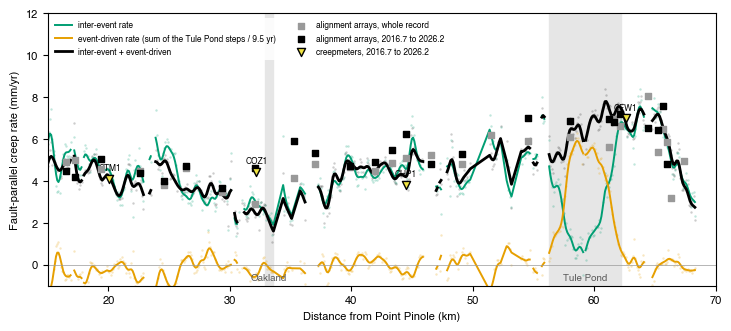

In [16]:
# [32]
fig, ax = plt.subplots(figsize=(7.2, 3.2), constrained_layout=True)
for name, (span_lo, span_hi) in (("Tule Pond", (len_lo, len_hi)), ("Oakland", (coz1_lo, coz1_hi))):
    ax.axvspan(span_lo, span_hi, color="0.9", zorder=0)
    ax.text(0.5 * (span_lo + span_hi), -0.75, name, ha="center", fontsize=7, color="0.35")
ax.scatter(slip_budget.km, slip_budget.secular, s=3, color=green, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.event_rate, s=3, color=orange, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.total, s=3, color="k", alpha=0.2, lw=0)
ax.plot(slip_budget.km, slip_budget.secular_smooth, color=green, lw=1.4, label="inter-event rate")
ax.plot(slip_budget.km, slip_budget.event_rate_smooth, color=orange, lw=1.4, label=f"event-driven rate (sum of the Tule Pond steps / {span:.1f} yr)")
ax.plot(slip_budget.km, slip_budget.total_smooth, color="k", lw=2.0, label="inter-event + event-driven")
ax.scatter(aa_rates.km, aa_rates.rate_longterm, marker="s", s=14, color="0.6", zorder=4, label="alignment arrays, whole record")
ax.scatter(aa_rates.km, aa_rates.rate_window, marker="s", s=14, color="k", zorder=5, label=f"alignment arrays, {t0:.1f} to {t1:.1f}")
cm_km_list = []
cm_rate_list = []
for km_cm, rate_cm in cm_rates.values():
    cm_km_list.append(km_cm)
    cm_rate_list.append(rate_cm)
ax.scatter(cm_km_list, cm_rate_list, marker="v", s=34, facecolor=gold, edgecolor="k", zorder=6, label=f"creepmeters, {t0:.1f} to {t1:.1f}")
for code, (km_cm, rate_cm) in cm_rates.items():
    ax.annotate(code, (km_cm, rate_cm), xytext=(0, 6), textcoords="offset points", ha="center", fontsize=6)
ax.set_xlim(*km_lim)
ax.set_ylim(-1, 12)
ax.axhline(0, color="0.6", lw=0.5)
ax.set_xlabel("Distance from Point Pinole (km)")
ax.set_ylabel("Fault-parallel creep rate (mm/yr)")
ax.legend(fontsize=6, loc="upper left", ncol=2)
f_budget = os.path.join(fig_dir, f"figS_slip_budget_{params}.png")
fig.savefig(f_budget, dpi=300)
fig.savefig(f_budget.replace(".png", ".pdf"))
print("Saved figure to:", f_budget)
plt.show()

## [33] REGISTER

The stats file `04_events_stats.txt` (every number above, in words) and the
registry rows `04_*` the paper quotes.

In [17]:
# [34]
stats_lines = ["04 EVENT DETECTION",
               f"stream {params}; stack +/-{stack_half_km:g} km along the trace of the section centre; matched filter {win_n} epochs, "
               f"{k_sigma:g} sigma; joint model linear + annual + steps; {nboot} block bootstraps (~{block_years:g} yr blocks)", ""]
for key, sol in solutions.items():
    stats_lines.append(f"[{segments[key]['label']}] stack n = {sol['n']}, rate {sol['coef'][1]:.2f} mm/yr, "
                       f"annual {np.hypot(sol['coef'][2], sol['coef'][3]):.2f} mm, rms {np.sqrt(sol['rss'] / len(sol['dates'])):.2f} mm")
    for event_fit in sol["fits"]:
        stats_lines.append(f"   onset window [{event_fit['onset_lo']:.4f}, {event_fit['onset_hi']:.4f}] "
                           f"amp {event_fit['amplitude_mm']:.2f} [{event_fit['amp_lo']:.2f}, {event_fit['amp_hi']:.2f}] mm")
stats_lines += ["", f"COZ1 control events ({len(coz1_events)}; label = onset day; the two large known ones at "
                f"{', '.join(f'{known_yr:g}' for known_yr in coz1_large_events_yr)} asserted among them):"]
for event in coz1_events.itertuples():
    stats_lines.append(f"   {event.onset_day}: window [{event.onset_lo:.4f}, {event.onset_hi:.4f}] ({event.onset_window_days:.0f} d), "
                       f"InSAR {event.amplitude_mm:.2f} [{event.amp_lo:.2f}, {event.amp_hi:.2f}] mm, statistic {event.detect_stat_mm:.2f} mm "
                       f"({event.detect_stat_mm / event.detect_sigma_mm:.2f} sigma), creepmeter step {event.creepmeter_step_mm:.2f} mm")
stats_lines += ["", "event-driven fraction (crossings within the stack half-width of the section centre):"]
for key, stats in frac_stats.items():
    stats_lines.append(f"   {segments[key]['label']}: n {stats['n']}, summed slip median {stats['sum_median']:.1f} mm, "
                       f"fraction median {stats['median']:.0f}%, 5-95% {stats['p5']:.0f} to {stats['p95']:.0f}%")
stats_lines += ["", f"window {w_lo:.1f} to {w_hi:.1f} km (re-centred on the cumulative-slip peak at {peak_km:.1f} km); "
                f"median of the per-crossing inter-event rates in the window {inter_event_rate_median:.2f} mm/yr",
                f"cumulative event slip peak {peak_cum:.1f} mm; flank threshold {length_threshold:.2f} mm (median {flank_median:.2f} + 3 x {flank_sigma:.2f})",
                f"length hosting the events: {len_lo:.1f} to {len_hi:.1f} km ({len_hi - len_lo:.1f} km, {len_n} crossings); "
                f"10%: {lengths['10pct'][1] - lengths['10pct'][0]:.1f} km; 20%: {lengths['20pct'][1] - lengths['20pct'][0]:.1f} km",
                "10-90% edge widths of the cumulative event slip: " + "; ".join(
                    f"{end} {width:.2f} km (90% at {km_90:.2f}, 10% at {km_10:.2f} km)" for end, (km_90, km_10, width) in edge_widths.items()),
                f"fraction peak {peak_frac:.1f}%"]
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    stats_lines.append(f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km ({hi_km - lo_km:.1f} km, {n_band} crossings); "
                       f"secular {result['secular']:.2f} mm/yr, annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm")
    step_texts = []
    for step_epoch, step, ci_lo, ci_hi in zip(step_epochs_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]):
        step_texts.append(f"{step_epoch:.3f} {step:.2f} [{ci_lo:.2f}, {ci_hi:.2f}]")
    stats_lines.append("   steps: " + ", ".join(step_texts) + f"; sum {np.sum(result['steps']):.1f}, mean {np.mean(result['steps']):.1f} mm")
stats_lines += ["", f"alignment arrays along the Tule Pond section ({len_lo - 1:.1f}-{len_hi + 1:.1f} km), refit over the InSAR window "
                f"{aa_window_text} (mm/yr, 1 sigma): " + ", ".join(
                    f"{row.code} {row.rate_window:.2f} +/- {row.rate_window_se:.2f} (n {row.n_window})" for row in in_section.itertuples())]
stats_lines += ["", "slip budget (mm/yr; arrays within 1 km of the block, refit over the InSAR window / whole record):"]
for name, block in budget.items():
    stats_lines.append(f"   {block['name']}: {block['lo']:.1f} to {block['hi']:.1f} km n {block['n']}: secular {block['secular']:.2f}, "
                       f"event {block['event_rate']:.2f}, total {block['total']:.2f} ({block['frac_pct']:.0f}%), arrays window "
                       f"{block['aa_window_mean']:.2f} (n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']})")
stats_lines += ["", f"seismicity (GrowClust) within {seis_max_dist_km:g} km, window {w_lo:.0f}-{w_hi:.0f} km: {n_seis_win} earthquakes, "
                f"{n_cre_win} repeaters, {n_cre_band} repeaters in the {100 * band_main:.0f}% band",
                *seis_count_lines, "catalogue spans of the events kept: " + "; ".join(catalogue_spans),
                f"hovmoller colour scale {vmin:.0f} to {vmax:.0f} mm"]
sidecar = REG.sidecar("04_events", stats_lines)

REG.register("04_n_events", len(tulepond_events), "count", 0, where="P3, abstract", cell="detect", sidecar=sidecar)
REG.register("04_detect_sigma_mm", float(tulepond_events.detect_sigma_mm[0]), "mm", 3, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_threshold_mm", k_sigma * float(tulepond_events.detect_sigma_mm[0]), "mm", 2, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_stack_n_crossings", solutions["TULEPOND"]["n"], "count", 0, where="M5", cell="detect", sidecar=sidecar)
labels = []
for step_epoch in step_epochs_tulepond:
    labels.append(f"{int(step_epoch)}")
for label, (_, event) in zip(labels, tulepond_events.iterrows()):
    REG.register(f"04_onset_lo_{label}", event.onset_lo, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_hi_{label}", event.onset_hi, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_window_days_{label}", event.onset_window_days, "d", 0, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_stack_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5", cell="joint-fit", sidecar=sidecar)
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    tag = f"band{int(band_frac * 100)}"
    REG.register(f"04_{tag}_lo_km", lo_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_hi_km", hi_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_width_km", hi_km - lo_km, "km", 1, where="P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_n_crossings", n_band, "count", 0, where="Fig1 caption", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_inter_event_mm_yr", result["secular"], "mm/yr", 2, where="P4, Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_annual_mm", result["annual"], "mm", 2, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_sum_mm", float(np.sum(result["steps"])), "mm", 1, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_mean_mm", float(np.mean(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_min_mm", float(np.min(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_max_mm", float(np.max(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    for label, step, ci_lo, ci_hi in zip(labels, result["steps"], result["ci_lo"], result["ci_hi"]):
        REG.register(f"04_{tag}_step_{label}_mm", step, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_lo", ci_lo, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_hi", ci_hi, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
REG.register("04_creep_length_km", len_hi - len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_lo_km", len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_hi_km", len_hi, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_n_crossings", len_n, "count", 0, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_threshold_mm", length_threshold, "mm", 2, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_10pct_km", lengths["10pct"][1] - lengths["10pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_20pct_km", lengths["20pct"][1] - lengths["20pct"][0], "km", 1, where="M6", cell="section-length", sidecar=sidecar)
for end, (km_90, km_10, width) in edge_widths.items():
    REG.register(f"04_edge_{end}_10_90_km", width, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_fraction_peak_pct", peak_frac, "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_median_pct", frac_stats["TULEPOND"]["median"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p5_pct", frac_stats["TULEPOND"]["p5"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p95_pct", frac_stats["TULEPOND"]["p95"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_event_slip_sum_median_mm", frac_stats["TULEPOND"]["sum_median"], "mm", 1, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_hovmoller_bg_rate_mm_yr", inter_event_rate_median, "mm/yr", 1, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
REG.register("04_hovmoller_vmax_mm", vmax, "mm", 0, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
for name, block in budget.items():
    for quantity in ("secular", "event_rate", "total"):
        REG.register(f"04_budget_{name}_{quantity.replace('secular', 'inter_event')}_mm_yr", block[quantity], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_event_pct", block["frac_pct"], "pct", 0, where="P4", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_window_mm_yr", block["aa_window_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_longterm_mm_yr", block["aa_longterm_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_n", block["aa_n"], "count", 0, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register("04_record_span_yr", span, "yr", 2, where="Fig1 caption", cell="budget", sidecar=sidecar)
# the arrays along the section, each refit over the InSAR window (its first and last day registered with them)
REG.register("04_aa_window_first_day", str(utils.decimal_year_to_day(t0).date()), "date", 0, where="P4 (array refit = InSAR window)", cell="budget", sidecar=sidecar)
REG.register("04_aa_window_last_day", str(utils.decimal_year_to_day(t1).date()), "date", 0, where="P4 (array refit = InSAR window)", cell="budget", sidecar=sidecar)
for array_row in in_section.itertuples():
    REG.register(f"04_aa_{array_row.code.lower()}_window_rate_mm_yr", array_row.rate_window, "mm/yr", 2, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
    REG.register(f"04_aa_{array_row.code.lower()}_window_rate_se_mm_yr", array_row.rate_window_se, "mm/yr", 2, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
    REG.register(f"04_aa_{array_row.code.lower()}_window_n_surveys", array_row.n_window, "count", 0, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
# (the point-onset intervals 04_interval_yr_* and 04_interval_mean_yr are no longer registered (2026-10-06): the
# paper's interval statistics are 11's only; they retire at this run's render)
REG.register("04_n_seis_window", n_seis_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_window", n_cre_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_band", n_cre_band, "count", 0, where="P3", cell="catalogues", sidecar=sidecar)
# the discussion's counts: within seis_max_dist_km of the trace over the InSAR period, in the section and in the band
for span_name in seis_count_spans:
    REG.register(f"04_n_seis_{span_name}", seis_counts[(span_name, "seis_all")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_seis_reloc_{span_name}", seis_counts[(span_name, "seis_reloc")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_{span_name}", seis_counts[(span_name, "cre_all")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_taira_{span_name}", seis_counts[(span_name, "cre_taira")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_wald_{span_name}", seis_counts[(span_name, "cre_wald")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
# the COZ1 control events ([10]: the two large known ones among them), labelled by onset day: 2019_01_09, ...
# (until 2026-10-05 by year, 04_control_coz1_*_2019 / _2022; a second 2022 event would collide; the year keys
# retire at this run's render)
coz1_detect_sigma_mm = float(coz1_events.detect_sigma_mm.iloc[0])      # one statistic sigma per stack (the same on every row)
assert (coz1_events.detect_sigma_mm == coz1_events.detect_sigma_mm.iloc[0]).all(), "the COZ1 rows carry different detection sigmas"
REG.register("04_control_coz1_n_events", len(coz1_events), "count", 0, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.register("04_control_coz1_detect_sigma_mm", coz1_detect_sigma_mm, "mm", 3, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.register("04_control_coz1_threshold_mm", k_sigma * coz1_detect_sigma_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
for event in coz1_events.itertuples():
    label = event.onset_day.replace("-", "_")                          # the onset day (unique, asserted in [10])
    REG.register(f"04_control_coz1_onset_{label}", event.onset_lo, "decyear", 3, where="M5 (control)", cell="detect", sidecar=sidecar)   # the step epoch = onset_lo
    REG.register(f"04_control_coz1_onset_hi_{label}", event.onset_hi, "decyear", 4, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_creepmeter_{label}_mm", event.creepmeter_step_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/04_event_detection/04_events_stats.txt
  registered 04_n_events = 5 count  -> P3, abstract


  registered 04_detect_sigma_mm = 0.824 mm  -> M5
  registered 04_threshold_mm = 2.47 mm  -> M5


  registered 04_stack_n_crossings = 39 count  -> M5
  registered 04_onset_lo_2017 = 2017.0986 decyear  -> P3


  registered 04_onset_hi_2017 = 2017.1315 decyear  -> P3
  registered 04_onset_window_days_2017 = 12 d  -> P3


  registered 04_stack_amp_2017_mm = 10.03 mm  -> M5


  registered 04_onset_lo_2019 = 2019.1863 decyear  -> P3
  registered 04_onset_hi_2019 = 2019.2027 decyear  -> P3


... (81 outputs left out)

  registered 04_control_coz1_onset_hi_2022_10_02 = 2022.8164 decyear  -> M5 (control)
  registered 04_control_coz1_amp_2022_10_02_mm = 1.39 mm  -> M5 (control)


  registered 04_control_coz1_creepmeter_2022_10_02_mm = 1.47 mm  -> M5 (control)


  01_prep_inputs: its latest run registered no numbers (sidecar newer than its last registry row); its keys are retired
  07b_uniform_model_tests: retired from the paper (TulePond_filepaths.retired_notebooks); its 26 keys are listed as RETIRED
Rendered registry to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/registry.txt'